# Name: Gangam Harsh
# Reg No: 23BDS0214
# Applied Data Exploration for Course Design Paradigms
## Course: BCSE331L | Exploratory Data Analysis

# Problem Statement: 
The objective is to perform a comprehensive exploratory data analysis on a realworld sales dataset using Python. The work covers data preparation, statistical
analysis, visualization, time series analysis, clustering, dimensionality reduction and model evaluation,
following the eight modules of the BCSE331L syllabus.

## Video Presentation Link:

https://drive.google.com/file/d/1brJorNlIjtro9ULRwvDv1TkFpOqXjWNz/view?usp=sharing

### Title of the Dataset

Exploratory Data Analysis of 1000 Sales Records Using Python

### About the Dataset

The 1000 Sales Records dataset contains sales transaction data from a fictional global business. It includes information about sales regions, countries, item types, sales channels, order priorities, order dates, shipping details, units sold, unit prices, unit costs, total revenue, total cost, total profit, and related transaction details.

The dataset contains 1,000 records and 14 columns, covering the period from January 2010 to July 2017. It includes both numerical and categorical attributes, making it suitable for exploring data distributions, identifying outliers, studying relationships between variables, performing correlation analysis, visualizing sales trends over time, applying clustering algorithms, reducing dimensionality, and developing regression models.

The primary objective of using this dataset is to understand sales and profitability patterns through statistical analysis and data visualization, while applying the concepts and techniques covered in the BCSE331L Exploratory Data Analysis syllabus.

### Dataset link

https://raw.githubusercontent.com/salemprakash/EDA/main/Data/1000%20Sales%20Records.csv

# Module 1: Introduction to Exploratory Data Analysis

## Definition:
Exploratory Data Analysis (EDA) is the process of examining a dataset using summary statistics and graphs to understand its structure, find patterns, detect outliers and check assumptions before
formal modelling.
## Objectives: 
understand the data, detect errors and outliers, discover relationships, and choose suitable
techniques for later analysis.


## Steps in EDA:
1. Define the question and collect the data.
2. Inspect structure (size, columns, data types).
3. Clean and transform the data (duplicates, missing values, types).
4. Summarize with statistics and visualize distributions and relationships.
5. Identify outliers and patterns, then draw conclusions.


# Data types
• Numerical – discrete: countable values (e.g. Units Sold)

• Numerical – continuous: measurable values on a continuum (e.g. Unit Price)

• Categorical: labels or groups (e.g. Region, Item Type).

## Measurement Scales

| Scale    | Property                         | Example                         |
|----------|----------------------------------|---------------------------------|
| Nominal  | Labels, no order                 | Region, Item Type               |
| Ordinal  | Ordered categories               | Order Priority (L &lt; M &lt; H &lt; C) |
| Interval | Ordered, equal gaps, no true zero | Calendar dates                 |
| Ratio    | Interval with true zero          | Units Sold, Total Profit        |

## EDA vs Classical vs Bayesian Analysis

| Aspect       | EDA              | Classical                  | Bayesian                    |
|--------------|------------------|----------------------------|-----------------------------|
| Starting point | Data           | Model, then data           | Prior belief, then data     |
| Focus        | Patterns, graphs | Hypothesis tests, p-values | Posterior distribution      |
| Parameters   | Not assumed      | Fixed unknown constants    | Random variables with priors |

## Software tools for EDA: 
Python (pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn), R, MATLAB,
Excel, Tableau and Power BI.

In [4]:
# Module 1: Import libraries required for exploratory data analysis

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['grid.alpha'] = 0.3
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [7]:
# Module 1: Load the sales dataset from the URL with a manual-upload fallback

URL = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/1000%20Sales%20Records.csv'
try:
    df = pd.read_csv(URL)
except Exception as error:
    print('Could not load from URL:', error)
    print('Upload the same CSV file manually.')
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])
print('Dataset loaded successfully')


Dataset loaded successfully


In [8]:
# Module 1: Preview the first records of the dataset
df.head()


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
0,Middle East and North Africa,Libya,Cosmetics,Offline,M,10/18/2014,686800706,10/31/2014,8446,437.20,263.33,3692591.20,2224085.18,1468506.02
1,North America,Canada,Vegetables,Online,M,11/7/2011,185941302,12/8/2011,3018,154.06,90.93,464953.08,274426.74,190526.34
2,Middle East and North Africa,Libya,Baby Food,Offline,C,10/31/2016,246222341,12/9/2016,1517,255.28,159.42,387259.76,241840.14,145419.62
3,Asia,Japan,Cereal,Offline,C,4/10/2010,161442649,5/12/2010,3322,205.70,117.11,683335.40,389039.42,294295.98
4,Sub-Saharan Africa,Chad,Fruits,Offline,H,8/16/2011,645713555,8/31/2011,9845,9.33,6.92,91853.85,68127.40,23726.45


In [9]:
# Module 1: Inspect dimensions, column names, data types and missing values
print('Shape (rows, columns):', df.shape)
print('Columns:', list(df.columns))
print()
df.info()
print()
print('Total missing values:', df.isnull().sum().sum())


Shape (rows, columns): (1000, 14)
Columns: ['Region', 'Country', 'Item Type', 'Sales Channel', 'Order Priority', 'Order Date', 'Order ID', 'Ship Date', 'Units Sold', 'Unit Price', 'Unit Cost', 'Total Revenue', 'Total Cost', 'Total Profit']

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Region          1000 non-null   str    
 1   Country         1000 non-null   str    
 2   Item Type       1000 non-null   str    
 3   Sales Channel   1000 non-null   str    
 4   Order Priority  1000 non-null   str    
 5   Order Date      1000 non-null   str    
 6   Order ID        1000 non-null   int64  
 7   Ship Date       1000 non-null   str    
 8   Units Sold      1000 non-null   int64  
 9   Unit Price      1000 non-null   float64
 10  Unit Cost       1000 non-null   float64
 11  Total Revenue   1000 non-null   float64
 12  Total Cost      1000 non-null

In [10]:
# Module 1: Classify columns as numerical, categorical, date or identifier
identifier_cols = ['Order ID']
date_cols = ['Order Date', 'Ship Date']
numeric_cols = [c for c in df.select_dtypes(include='number').columns if c not in identifier_cols]
categorical_cols = [c for c in df.columns if c not in numeric_cols + date_cols + identifier_cols]
print('Identifier :', identifier_cols)
print('Date :', date_cols)
print('Numerical :', numeric_cols)
print('Categorical:', categorical_cols)
print()
print('Unique values per categorical column')
print(df[categorical_cols].nunique())

Identifier : ['Order ID']
Date : ['Order Date', 'Ship Date']
Numerical : ['Units Sold', 'Unit Price', 'Unit Cost', 'Total Revenue', 'Total Cost', 'Total Profit']
Categorical: ['Region', 'Country', 'Item Type', 'Sales Channel', 'Order Priority']

Unique values per categorical column
Region              7
Country           185
Item Type          12
Sales Channel       2
Order Priority      4
dtype: int64


## Data Dictionary

| Column                         | Type                     | Scale   | Description                                      |
|--------------------------------|--------------------------|---------|--------------------------------------------------|
| Region, Country                | Categorical              | Nominal | Geographic location of the sale                  |
| Item Type                      | Categorical              | Nominal | Product category                                 |
| Sales Channel                  | Categorical              | Nominal | Online or Offline                                |
| Order Priority                 | Categorical              | Ordinal | L, M, H, C                                       |
| Order Date, Ship Date          | Date                     | Interval| Order and shipping dates                         |
| Order ID                       | Identifier               | Nominal | Unique order number (not analysed numerically)   |
| Units Sold                     | Numerical (discrete)     | Ratio   | Quantity sold                                    |
| Unit Price, Unit Cost          | Numerical (continuous)   | Ratio   | Per-unit selling price and cost                  |
| Total Revenue, Total Cost, Total Profit | Numerical (continuous) | Ratio | Derived money amounts                            |

**Suitability and limitations:** The dataset has a genuine date column, so real time series analysis is possible. Unit Price and Unit Cost take only a few distinct values (one per item type), and Total Revenue, Total Cost and Total Profit are calculated from other columns, so strong correlations are partly built into the data.

# Module 2: Data Transformation


Data transformation converts raw data into a clean, consistent form suitable for analysis. The raw data
is preserved in df_raw, and all cleaning is done on a copy called df_clean.
Techniques used: deduplication, replacing values, type conversion, discretization/binning, and missingdata handling.

In [11]:
 # Module 2: Preserve the raw data and check for duplicate records
df_raw = df.copy()
df_clean = df.copy()
print('Duplicate rows:', df_clean.duplicated().sum())
print('Duplicate Order IDs:', df_clean['Order ID'].duplicated().sum())
df_clean = df_clean.drop_duplicates()
print('Rows after deduplication:', len(df_clean))


Duplicate rows: 0
Duplicate Order IDs: 0
Rows after deduplication: 1000


In [13]:
# Module 2: Replace coded values with readable labels
priority_map = {'L': 'Low', 'M': 'Medium', 'H': 'High', 'C': 'Critical'}
df_clean['Order Priority'] = df_clean['Order Priority'].replace(priority_map)
df_clean['Sales Channel'] = df_clean['Sales Channel'].str.strip().str.title()
print('Values replaced in Order Priority:', (df_raw['Order Priority'] != df_clean['Order Priority']).sum())
print(df_clean['Order Priority'].value_counts())


Values replaced in Order Priority: 1000
Order Priority
Low         268
Critical    262
Medium      242
High        228
Name: count, dtype: int64


In [15]:
# Module 2: Convert data types for dates, identifier and ordered categories
df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'], format='%m/%d/%Y')
df_clean['Ship Date'] = pd.to_datetime(df_clean['Ship Date'], format='%m/%d/%Y')
df_clean['Order ID'] = df_clean['Order ID'].astype(str)
df_clean['Order Priority'] = pd.Categorical(df_clean['Order Priority'], categories=['Low', 'Medium',
'High', 'Critical'], ordered=True)
print(df_clean.dtypes)


Region                       str
Country                      str
Item Type                    str
Sales Channel                str
Order Priority          category
Order Date        datetime64[us]
Order ID                     str
Ship Date         datetime64[us]
Units Sold                 int64
Unit Price               float64
Unit Cost                float64
Total Revenue            float64
Total Cost               float64
Total Profit             float64
dtype: object


### Discretization and binning
It converts a continuous variable into intervals. Here pd.cut creates equalwidth bins for Units Sold with defined labels, and pd.qcut creates equal-frequency bins (quartiles) for Total Revenue.

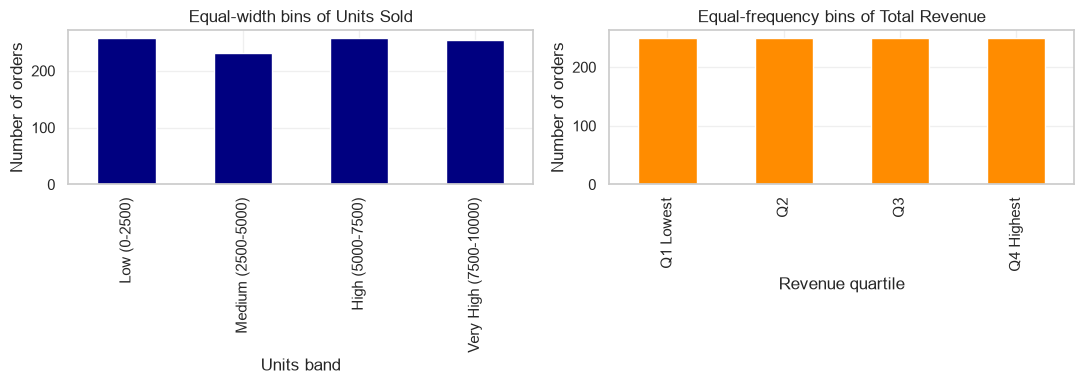

In [17]:
# Module 2: Discretize Units Sold and Total Revenue into bins
unit_bins = [0, 2500, 5000, 7500, 10000]
unit_labels = ['Low (0-2500)', 'Medium (2500-5000)', 'High (5000-7500)', 'Very High (7500-10000)']
df_clean['Units Band'] = pd.cut(df_clean['Units Sold'], bins=unit_bins, labels=unit_labels)
df_clean['Revenue Quartile'] = pd.qcut(df_clean['Total Revenue'], q=4, labels=['Q1 Lowest', 'Q2', 'Q3',
'Q4 Highest'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_clean['Units Band'].value_counts().sort_index().plot(kind='bar', color='navy', ax=axes[0])
axes[0].set_title('Equal-width bins of Units Sold')
axes[0].set_xlabel('Units band')
axes[0].set_ylabel('Number of orders')
df_clean['Revenue Quartile'].value_counts().sort_index().plot(kind='bar', color='darkorange',
ax=axes[1])
axes[1].set_title('Equal-frequency bins of Total Revenue')
axes[1].set_xlabel('Revenue quartile')
axes[1].set_ylabel('Number of orders')
plt.tight_layout()
plt.show()


# Interpretation: 
Units Sold is almost uniformly spread (skewness about −0.05), so the equal-width bands
hold similar numbers of orders, while the quartile bins of Total Revenue are balanced by construction. Bin edges were chosen by hand, so different edges would give different counts.

# Missing data. Missing values are classified as MCAR (missing completely at random), MAR (missing at
random) or MNAR (missing not at random).
The original dataset has no missing values. To demonstrate the techniques, a copy of the data is given
artificially missing values (about 5% in three columns, completely at random). This is a demonstration only and is not a property of the real data.

Units Sold      53
Unit Price      38
Total Profit    54
Region           0
dtype: int64


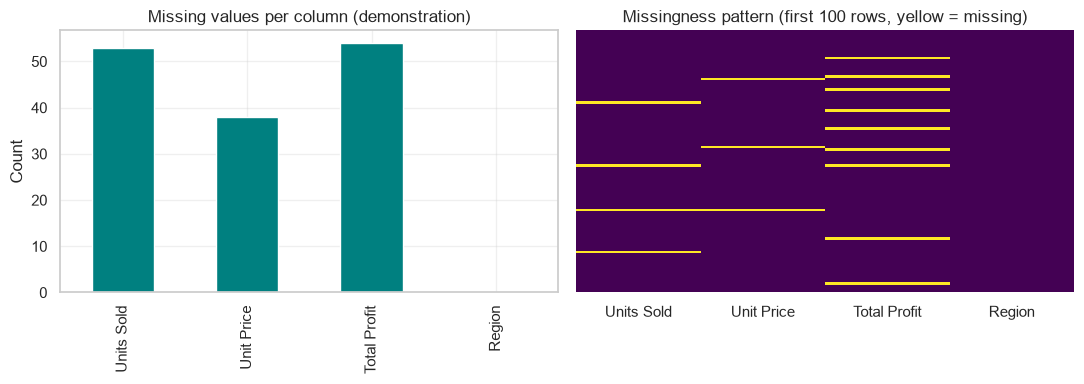

In [20]:
# Module 2: Create a demonstration copy with artificially missing values and visualize them

df_missing = df_clean[['Units Sold', 'Unit Price', 'Total Profit', 'Region']].copy()
rng = np.random.default_rng(RANDOM_STATE)
for column in ['Units Sold', 'Unit Price', 'Total Profit']:
    df_missing.loc[rng.random(len(df_missing)) < 0.05, column] = np.nan
missing_count = df_missing.isnull().sum()
print(missing_count)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
missing_count.plot(kind='bar', color='teal', ax=axes[0])
axes[0].set_title('Missing values per column (demonstration)')
axes[0].set_ylabel('Count')
sns.heatmap(df_missing.head(100).isnull(), cbar=False, cmap='viridis', yticklabels=False, ax=axes[1])
axes[1].set_title('Missingness pattern (first 100 rows, yellow = missing)')
plt.tight_layout()
plt.show()


## Traditional methods for handling missing data

• Deletion: remove rows (listwise) or columns with missing values. Simple, but loses information and
can bias results unless data is MCAR.

• Mean imputation: replace with the column mean. Suitable for symmetric data, but reduces variance.

• Median imputation: replace with the median. Robust to skewed data and outliers.

• Mode imputation: replace with the most frequent value. Used for categorical data.

## Limitation: 
simple imputation ignores relationships between variables and shrinks the spread of the data.

In [23]:
# Module 2: Apply mean, median and mode imputation and compare with the original values

true_values = df_clean.loc[df_missing.index, ['Units Sold', 'Unit Price', 'Total Profit']]
mean_filled = df_missing[['Units Sold', 'Unit Price', 'Total Profit']].fillna(df_missing[['Units Sold','Unit Price', 'Total Profit']].mean())
median_filled = df_missing[['Units Sold', 'Unit Price', 'Total Profit']].fillna(df_missing[['Units Sold', 'Unit Price', 'Total Profit']].median())
mode_filled = df_missing[['Units Sold', 'Unit Price', 'Total Profit']].fillna(df_missing[['Units Sold','Unit Price', 'Total Profit']].mode().iloc[0])
comparison = pd.DataFrame({
    'Original mean': true_values.mean(),
    'Mean-imputed mean': mean_filled.mean(),
    'Median-imputed mean': median_filled.mean(),
    'Original std': true_values.std(),
    'Mean-imputed std': mean_filled.std(),
    'Median-imputed std': median_filled.std()})
comparison.round(2)


,Original mean,Mean-imputed mean,Median-imputed mean,Original std,Mean-imputed std,Median-imputed std
Units Sold,5053.99,5050.98,5059.94,2901.38,2820.00,2820.25
Unit Price,262.11,262.66,258.53,216.02,211.54,212.56
Total Profit,391202.61,395265.38,388988.06,383640.19,376734.14,377650.12


## Interpretation: 

Imputation barely changes the means (e.g. Units Sold 5053.99 to about 5051-5060; Total
Profit 391,203 to about 388,988-395,265), but the standard deviations shrink (Units Sold 2901 to about
2820) because every filled value sits at the centre. This confirms the limitation: simple imputation preserves the centre but understates the spread.


In [24]:
 # Module 2: Remove rows with missing values and report the data loss
rows_before = len(df_missing)
df_dropped = df_missing.dropna()
print('Rows before:', rows_before)
print('Rows after listwise deletion:', len(df_dropped))
print('Rows lost: %d (%.1f%%)' % (rows_before - len(df_dropped), 100 * (rows_before - len(df_dropped))
/ rows_before))

Rows before: 1000
Rows after listwise deletion: 862
Rows lost: 138 (13.8%)


## Maximum Likelihood Estimation (MLE):
MLE chooses the parameter values that make the observed
data most probable. For independent observations 𝑥1
, … , 𝑥𝑛 with density 𝑓(𝑥 ∣ 𝜃):


𝐿(𝜃) =
𝑛
∏
𝑖=1
𝑓(𝑥𝑖
∣ 𝜃), ̂ 𝜃 = arg max
𝜃
ln𝐿(𝜃)


For a normal distribution the maximizing values are ̂𝜇 = 1
𝑛 ∑ 𝑥𝑖 and ̂𝜎
2 =
1
𝑛 ∑(𝑥𝑖 − ̂𝜇)2
. MLE is also the
basis of principled missing-data methods, where parameters are estimated from all available data instead
of filling in single values.
Below, a normal model is fitted to Units Sold by minimizing the negative log-likelihood numerically, and
the result is checked against the closed-form solution.


Numerical MLE : mu = 5053.32, sigma = 2899.69
Closed form : mu = 5053.99, sigma = 2899.92


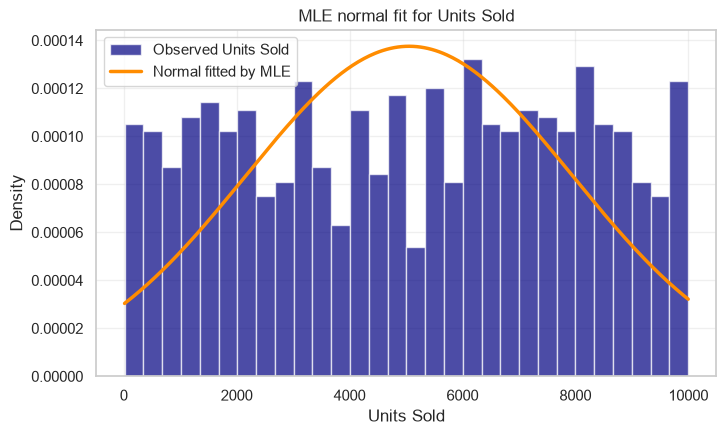

In [26]:
# Module 2: Estimate normal distribution parameters for Units Sold using MLE

from scipy.optimize import minimize
units = df_clean['Units Sold'].values
def negative_log_likelihood(params):
    mu, sigma = params
    return -np.sum(stats.norm.logpdf(units, loc=mu, scale=sigma))
result = minimize(negative_log_likelihood, x0=[units.mean() + 100, units.std() + 100], bounds=[(None,
None), (1, None)])
print('Numerical MLE : mu = %.2f, sigma = %.2f' % tuple(result.x))
print('Closed form : mu = %.2f, sigma = %.2f' % (units.mean(), units.std()))
x_axis = np.linspace(units.min(), units.max(), 300)
plt.hist(units, bins=30, density=True, color='navy', alpha=0.7, label='Observed Units Sold')
plt.plot(x_axis, stats.norm.pdf(x_axis, *result.x), color='darkorange', linewidth=2.5, label='Normal fitted by MLE')
plt.title('MLE normal fit for Units Sold')
plt.xlabel('Units Sold')
plt.ylabel('Density')
plt.legend()
plt.show()


## Interpretation:
The numerical MLE (μ ≈ 5053.3, σ ≈ 2899.6) agrees with the closed-form values
(5053.99, 2899.92), which verifies the optimization. However, Units Sold is flat rather than bell-shaped
(kurtosis ≈ −1.2), so a normal model is only a rough description. MLE finds the best parameters within
the chosen model, not the best model.

In [27]:
# Module 2: Compare data quality before and after cleaning
quality = pd.DataFrame({
'Raw data': [len(df_raw), df_raw.duplicated().sum(), df_raw.isnull().sum().sum(), df_raw.shape[1]],
'Cleaned data': [len(df_clean), df_clean.duplicated().sum(), df_clean.isnull().sum().sum(),
df_clean.shape[1]]},
index=['Rows', 'Duplicate rows', 'Missing values', 'Columns'])
quality


,Raw data,Cleaned data
Rows,1000,1000
Duplicate rows,0,0
Missing values,0,0
Columns,14,16


## Observation: 
The raw data already had no missing values and no duplicates, so cleaning did not remove
any rows. The two extra columns in the cleaned data are the derived bin columns. The missing-value work
above was a demonstration on an artificially modified copy.


# Module 3: Correlation Analysis and Time Series Analysis

### Types of analysis
• Univariate: one variable (distribution, summary)

• Bivariate: two variables (relationship, comparison)

• Multivariate: three or more variables at once.

count       1000.00
mean      391202.61
std       383640.19
min          532.61
25%        98376.12
50%       277225.98
75%       548456.84
max      1726181.36
Name: Total Profit, dtype: float64


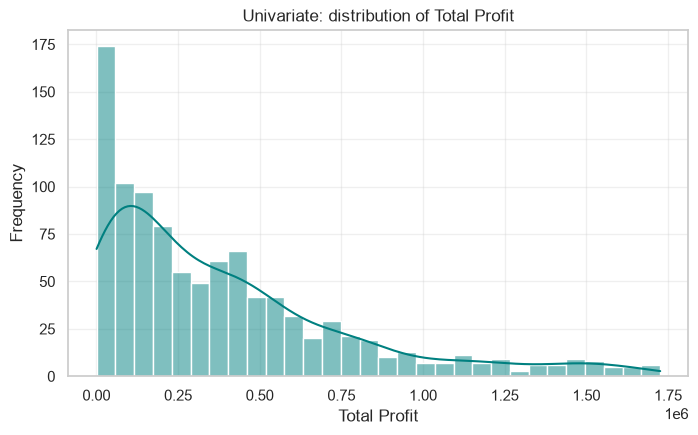

In [28]:
# Module 3: Univariate analysis of Total Profit
print(df_clean['Total Profit'].describe().round(2))
sns.histplot(df_clean['Total Profit'], bins=30, kde=True, color='teal')
plt.title('Univariate: distribution of Total Profit')
plt.xlabel('Total Profit')
plt.ylabel('Frequency')
plt.show()


### Interpretation: 

Total Profit is right-skewed: the mean (about 391,203) is well above the median (about
277,226), with a maximum of about 1.73 million. Most orders earn modest profit and a few earn very large
profit.

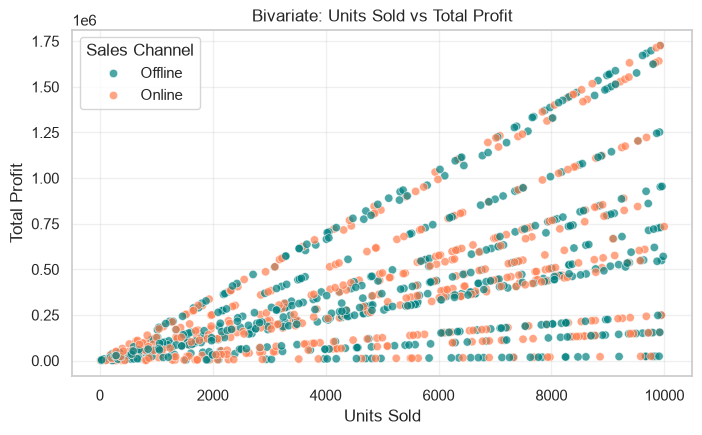

In [29]:
# Module 3: Bivariate analysis of Units Sold and Total Profit by Sales Channel
sns.scatterplot(data=df_clean, x='Units Sold', y='Total Profit', hue='Sales Channel', palette=['teal',
'coral'], alpha=0.7)
plt.title('Bivariate: Units Sold vs Total Profit')
plt.xlabel('Units Sold')
plt.ylabel('Total Profit')
plt.show()


### Interpretation: 

Total Profit tends to rise with Units Sold, but the points fall along several straight lines
radiating from the origin rather than one line. This is because profit per unit is fixed for each item type,
so each item type forms its own line with its own slope. Online and offline orders overlap with no obvious
separation.


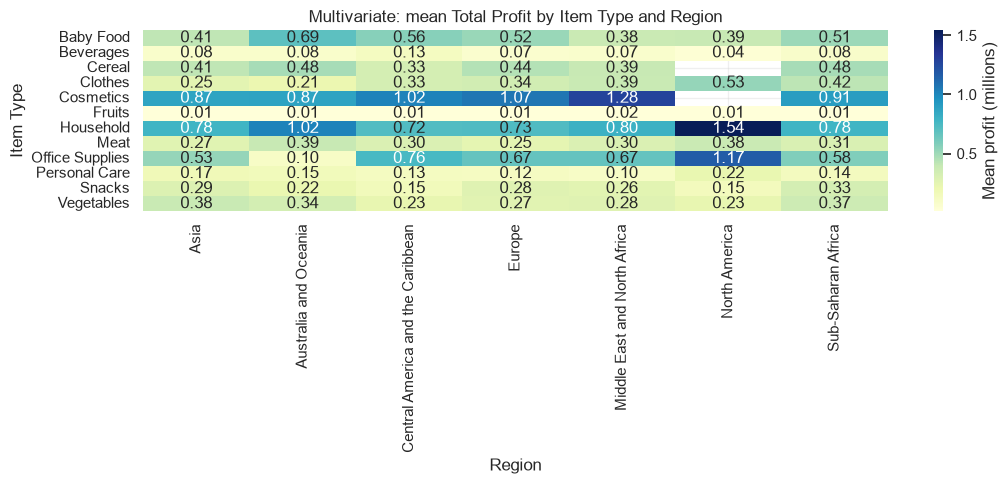

In [30]:
# Module 3: Multivariate analysis of average profit by Region, Sales Channel and Item Type

pivot = df_clean.pivot_table(values='Total Profit', index='Item Type', columns='Region', aggfunc='mean')
plt.figure(figsize=(11, 5))
sns.heatmap(pivot / 1e6, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Mean profit (millions)'})
plt.title('Multivariate: mean Total Profit by Item Type and Region')
plt.xlabel('Region')
plt.ylabel('Item Type')
plt.tight_layout()
plt.show()


### Interpretation: 
Mean profit varies strongly across item types (some cells are several times larger than
others) and is more differentiated by item type than by region. Individual cells rest on few orders, so single
cells should be read with caution.

### Time series analysis (TSA) 
studies observations ordered in time. Its main characteristics are:

• Trend: long-term increase or decrease.

• Seasonality: regular pattern repeating at a fixed period (e.g. yearly).

• Cyclic pattern: rises and falls with no fixed period.

• Irregular variation: random noise.

The dataset has a genuine Order Date column, so real calendar-based analysis is possible. Note that each
row is one order, so orders must be aggregated (grouped and resampled) to form a time series.

In [31]:
# Module 3: Sort by date and set Order Date as a time-based index
ts = df_clean.sort_values('Order Date').set_index('Order Date')
print('Date range:', ts.index.min().date(), 'to', ts.index.max().date())
print('Number of orders:', len(ts))
print(ts.loc['2012-01-01':'2012-03-31', ['Item Type', 'Total Revenue']].head())


Date range: 2010-01-01 to 2017-07-26
Number of orders: 1000
             Item Type  Total Revenue
Order Date                           
2012-01-02   Baby Food       67393.92
2012-01-03      Snacks     1228879.32
2012-01-03  Vegetables      481745.62
2012-01-05   Household     1097967.61
2012-01-05        Meat     3705459.87


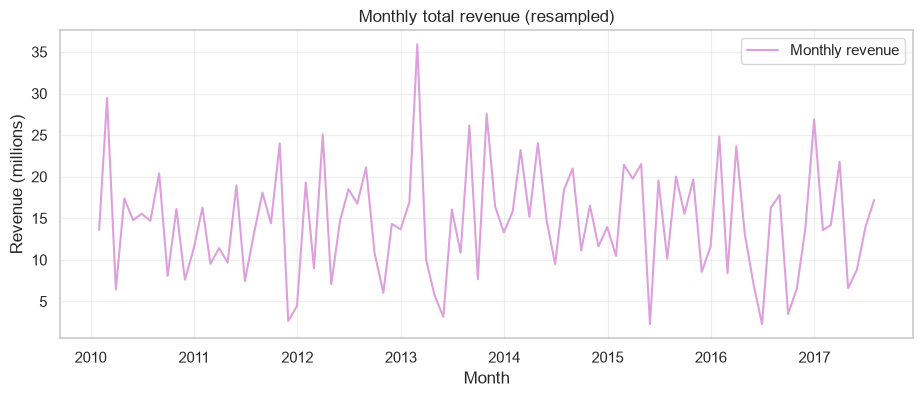

In [38]:
 # Module 3: Resample to monthly revenue and visualize the time series
monthly_revenue = ts['Total Revenue'].resample('ME').sum()
plt.figure(figsize=(11, 4))
plt.plot(monthly_revenue.index, monthly_revenue / 1e6, color='plum', linewidth=1.5, label='Monthly revenue')
plt.title('Monthly total revenue (resampled)')
plt.xlabel('Month')
plt.ylabel('Revenue (millions)')
plt.legend()
plt.show()


### Interpretation: 
Monthly revenue is highly irregular, because each month contains only a handful of orders
(1000 orders over about 7.5 years). Large single orders cause the spikes.

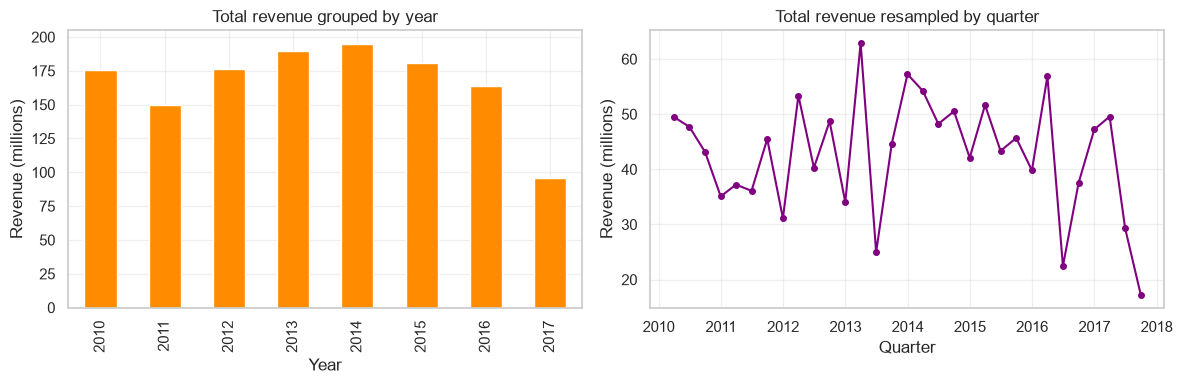

In [39]:
# Module 3: Group time series data by year and by quarter
yearly = ts.groupby(ts.index.year)['Total Revenue'].sum() / 1e6
quarterly = ts['Total Revenue'].resample('QE').sum() / 1e6
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
yearly.plot(kind='bar', color='darkorange', ax=axes[0])
axes[0].set_title('Total revenue grouped by year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Revenue (millions)')
axes[1].plot(quarterly.index, quarterly.values, color='purple', marker='o', markersize=4)
axes[1].set_title('Total revenue resampled by quarter')
axes[1].set_xlabel('Quarter')
axes[1].set_ylabel('Revenue (millions)')
plt.tight_layout()
plt.show()


### Interpretation: 
Yearly revenue ranges between about 150 and 195 million for 2010–2016, peaking in
2014 (about 195 million). The 2017 bar (about 96 million) is lower because the data end on 26 July 2017,
so 2017 is an incomplete year and should not be read as a decline.

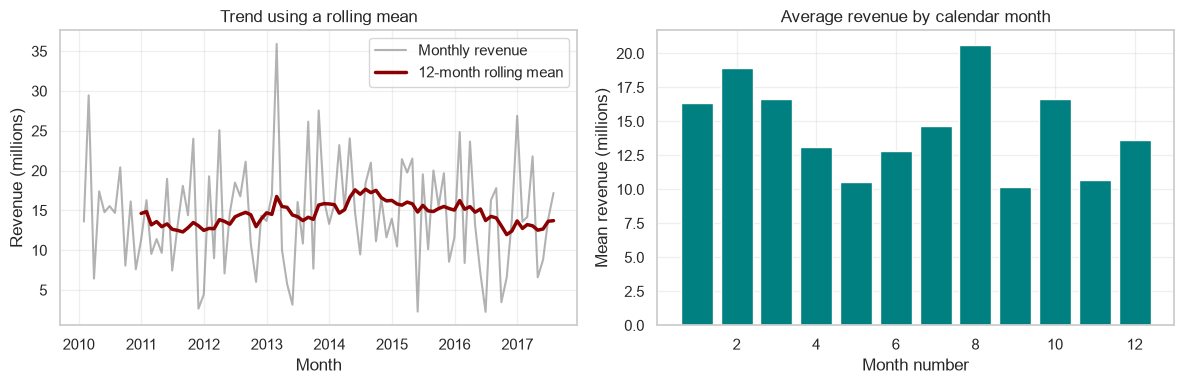

Lag-1 autocorrelation of monthly revenue: -0.181
Lag-12 autocorrelation of monthly revenue: 0.089


In [41]:
 # Module 3: Rolling statistics, seasonality by month and lag-1 autocorrelation
rolling_mean = monthly_revenue.rolling(window=12).mean()
month_average = monthly_revenue.groupby(monthly_revenue.index.month).mean() / 1e6
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly_revenue.index, monthly_revenue / 1e6, color='gray', alpha=0.6, label='Monthly revenue')
axes[0].plot(rolling_mean.index, rolling_mean / 1e6, color='darkred', linewidth=2.5, label='12-month rolling mean')
axes[0].set_title('Trend using a rolling mean')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue (millions)')
axes[0].legend()
axes[1].bar(month_average.index, month_average.values, color='teal')
axes[1].set_title('Average revenue by calendar month')
axes[1].set_xlabel('Month number')
axes[1].set_ylabel('Mean revenue (millions)')
plt.tight_layout()
plt.show()
print('Lag-1 autocorrelation of monthly revenue: %.3f' % monthly_revenue.autocorr(lag=1))
print('Lag-12 autocorrelation of monthly revenue: %.3f' % monthly_revenue.autocorr(lag=12))


### Interpretation: 
The 12-month rolling mean shows no strong long-term trend. The month-of-year averages
vary (highest in August, lowest in September), but with only 7–8 observations per month and irregular
orders this is more likely random variation than genuine seasonality. The autocorrelations are weak (lag1 = −0.181, lag-12 = 0.089), so monthly revenue shows little persistence. Cyclic patterns cannot be
established from this short, noisy series

## Correlation analysis. 
Correlation measures the strength and direction of association between two variables, from −1 to +1.

• Pearson (linear): 𝑟 =
∑(𝑥𝑖 − ̄𝑥)(𝑦𝑖 − ̄𝑦)/
√∑(𝑥𝑖 − ̄𝑥)^2 ∑(𝑦𝑖 − ̄𝑦)^2

• Spearman (monotonic): Pearson correlation applied to the ranks of the data.
Rough guide: |𝑟| < 0.3 weak, 0.3–0.7 moderate, > 0.7 strong. 
Correlation does not imply causation, and this is observational data.


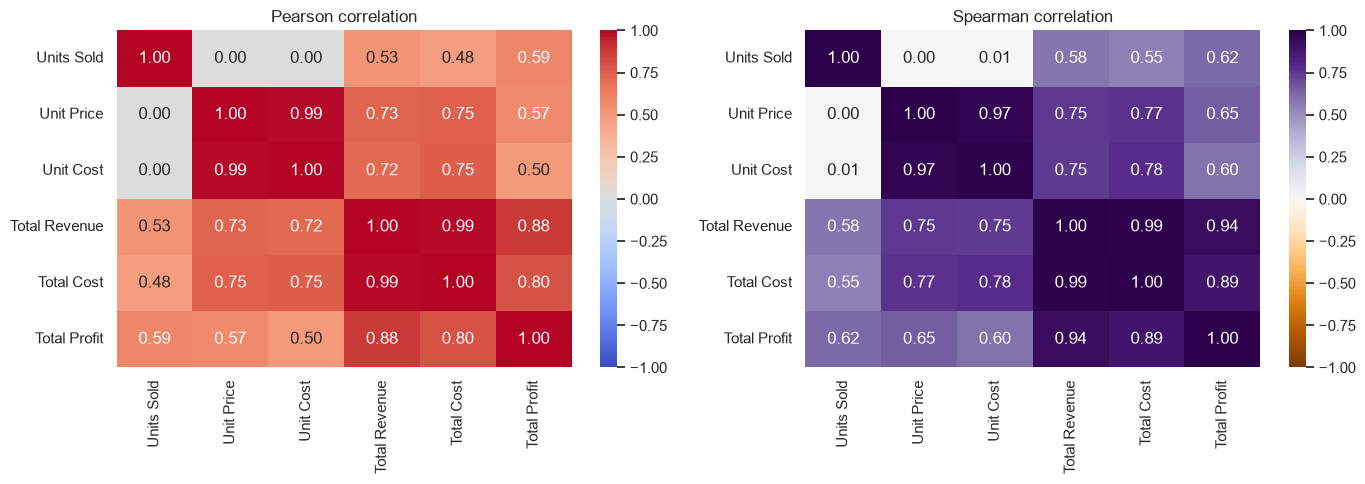

In [42]:
# Module 3: Compute and plot Pearson and Spearman correlation matrices
pearson_matrix = df_clean[numeric_cols].corr(method='pearson')
spearman_matrix = df_clean[numeric_cols].corr(method='spearman')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson correlation')
sns.heatmap(spearman_matrix, annot=True, fmt='.2f', cmap='PuOr', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman correlation')
plt.tight_layout()
plt.show()

### Interpretation:
Units Sold and Unit Price are uncorrelated (r ≈ 0.00). Total Profit is moderately correlated with both Units Sold (Pearson about 0.59) and Unit Price (about 0.57), and Spearman values are similar (Units Sold with Total Profit about 0.62), so the relationships are roughly monotonic. Total Revenue, Total Cost and Total Profit are strongly related to each other because they are calculated from the same inputs, so those high values are structural, not discoveries. These are observational associations and do not show causation.


# Module 4: Data Summarization and Visualization

### Statistical summary measures
• Mean ̄𝑥 = 1/
𝑛 ∑ 𝑥𝑖
; median is the middle value; mode is the most frequent value.

• Variance 𝑠
2 =
1/
𝑛−1 ∑(𝑥𝑖 − ̄𝑥)^2

standard deviation 𝑠 = √
𝑠^
2.

• Range = max − min; quartiles 𝑄1
, 𝑄2
, 𝑄3
; IQR = 𝑄3 − 𝑄1
.
• Skewness measures asymmetry (0 for symmetric data)
kurtosis measures tail heaviness (excess kurtosis is 0 for a normal distribution).


In [43]:
# Module 4: Compute statistical summary measures for numerical columns
summary = df_clean[numeric_cols].describe().T
summary['mode'] = df_clean[numeric_cols].mode().iloc[0]
summary['variance'] = df_clean[numeric_cols].var()
summary['range'] = summary['max'] - summary['min']
summary['IQR'] = summary['75%'] - summary['25%']
summary['skewness'] = df_clean[numeric_cols].skew()
summary['kurtosis'] = df_clean[numeric_cols].kurt()
summary.round(2)


,count,mean,std,min,25%,50%,75%,max,mode,variance,range,IQR,skewness,kurtosis
Units Sold,1000.0,5053.99,2901.38,13.00,2420.25,5184.00,7536.75,9998.00,6283.00,8.417979e+06,9985.00,5116.50,-0.05,-1.22
Unit Price,1000.0,262.11,216.02,9.33,81.73,154.06,421.89,668.27,47.45,4.666510e+04,658.94,340.16,0.79,-0.73
Unit Cost,1000.0,184.97,175.29,6.92,56.67,97.44,263.33,524.96,31.79,3.072634e+04,518.04,206.66,0.95,-0.60
Total Revenue,1000.0,1327321.84,1486514.56,2043.25,281191.90,754939.18,1733502.75,6617209.54,90211.77,2.209726e+12,6615166.29,1452310.85,1.63,2.07
Total Cost,1000.0,936119.23,1162570.75,1416.75,164931.88,464726.06,1141750.09,5204978.40,66909.48,1.351571e+12,5203561.65,976818.22,1.80,2.56
Total Profit,1000.0,391202.61,383640.19,532.61,98376.12,277225.98,548456.84,1726181.36,23302.29,1.471798e+11,1725648.75,450080.72,1.41,1.60


### Interpretation: 
Units Sold is nearly symmetric (skewness −0.05) with a flat shape (kurtosis −1.22). The
money variables are right-skewed (skewness 0.79 to 1.80) and the totals have positive kurtosis, i.e. a few
very large values. For these, the mean exceeds the median (Total Profit mean 391,203 vs median 277,226),
so the median and IQR describe the typical order better than the mean.


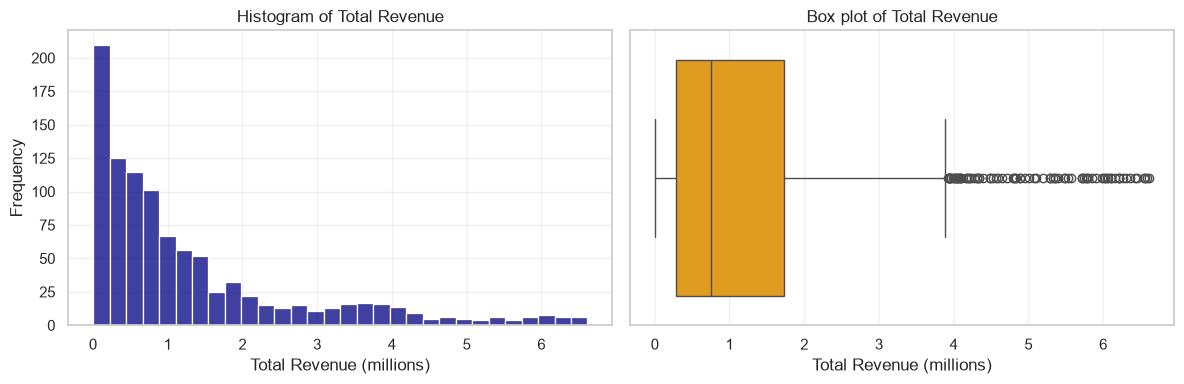

In [44]:
# Module 4: One-dimensional analysis with a histogram and box plot of Total Revenue
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean['Total Revenue'] / 1e6, bins=30, color='navy', ax=axes[0])
axes[0].set_title('Histogram of Total Revenue')
axes[0].set_xlabel('Total Revenue (millions)')
axes[0].set_ylabel('Frequency')
sns.boxplot(x=df_clean['Total Revenue'] / 1e6, color='orange', ax=axes[1])
axes[1].set_title('Box plot of Total Revenue')
axes[1].set_xlabel('Total Revenue (millions)')
plt.tight_layout()
plt.show()

### Interpretation: 
Total Revenue is strongly right-skewed (skewness 1.63): the median is about 0.75 million
while the maximum is about 6.6 million. The box plot marks the high values as outliers on the right side
only.

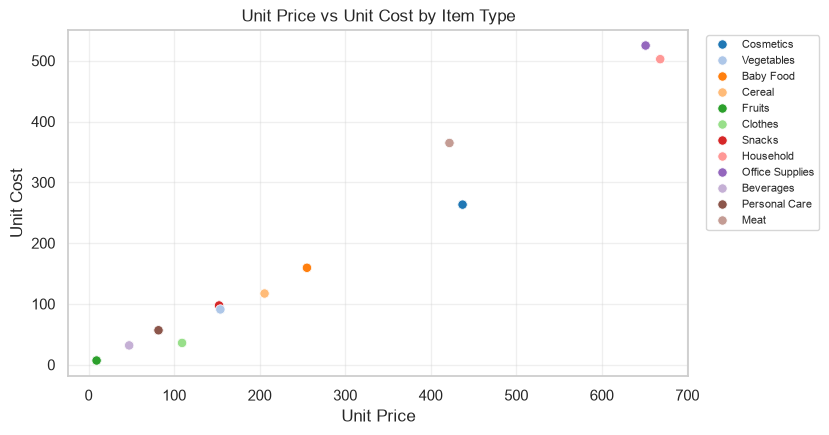

In [45]:
# Module 4: Two-dimensional analysis with a scatter plot of Unit Price and Unit Cost
sns.scatterplot(data=df_clean, x='Unit Price', y='Unit Cost', hue='Item Type', palette='tab20', s=45)
plt.title('Unit Price vs Unit Cost by Item Type')
plt.xlabel('Unit Price')
plt.ylabel('Unit Cost')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()

### Interpretation: 
Unit Price and Unit Cost are almost perfectly linearly related (r ≈ 0.99), and each item
type appears at one fixed point. This means price and cost are properties of the item type, not independent
variables.


## Contingency table (cross-tabulation):
counts observations for each combination of two categorical variables. The chi-square test of independence checks whether the two variables are associated.


Sales Channel                      Offline  Online   All
Region                                                  
Asia                                    69      67   136
Australia and Oceania                   47      32    79
Central America and the Caribbean       61      38    99
Europe                                 135     132   267
Middle East and North Africa            65      73   138
North America                            8      11    19
Sub-Saharan Africa                     135     127   262
All                                    520     480  1000

Chi-square = 7.849, degrees of freedom = 6, p-value = 0.2494


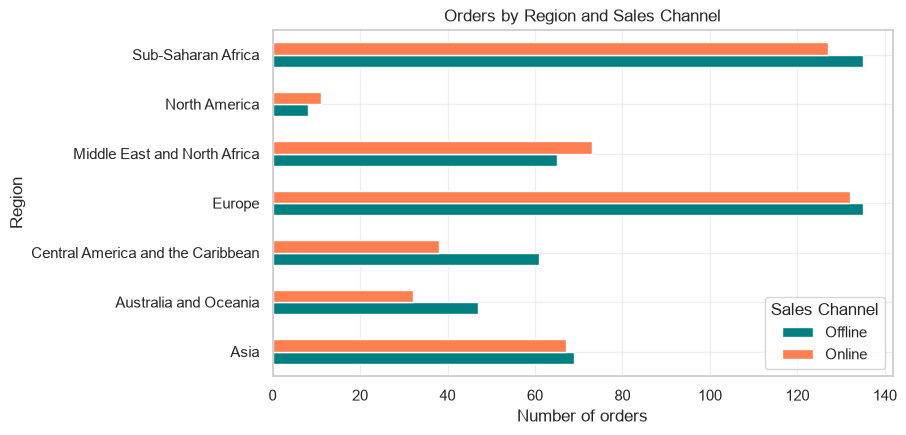

In [48]:
# Module 4: Build a contingency table of Region and Sales Channel with a chi-square test
contingency = pd.crosstab(df_clean['Region'], df_clean['Sales Channel'], margins=True)
print(contingency)
chi2, p_value, dof, expected = stats.chi2_contingency(pd.crosstab(df_clean['Region'], df_clean['Sales Channel']))
print('\nChi-square = %.3f, degrees of freedom = %d, p-value = %.4f' % (chi2, dof, p_value))
pd.crosstab(df_clean['Region'], df_clean['Sales Channel']).plot(kind='barh', color=['teal', 'coral'])
plt.title('Orders by Region and Sales Channel')
plt.xlabel('Number of orders')
plt.ylabel('Region')
plt.show()

### Interpretation: 
The chi-square test gives χ² = 7.849 with 6 degrees of freedom and p = 0.249. Since p >
0.05, there is no evidence of an association between Region and Sales Channel. Europe and Sub-Saharan
Africa have the most orders, and North America has only 19.


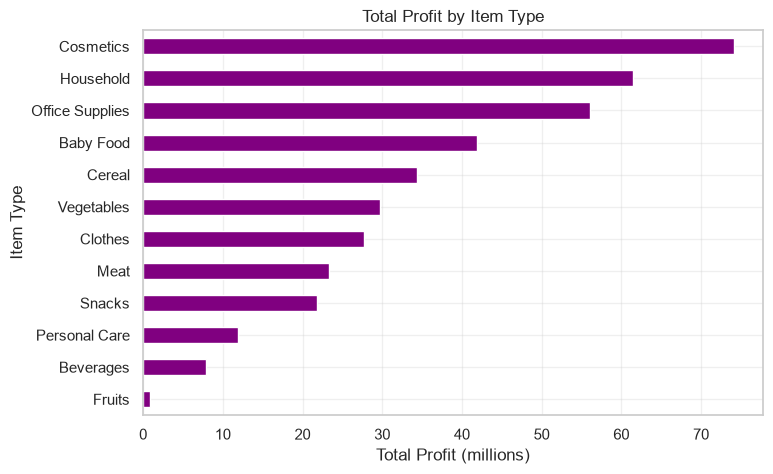

In [49]:
# Module 4: Bar plot of total profit by Item Type
profit_by_item = df_clean.groupby('Item Type')['Total Profit'].sum().sort_values() / 1e6
profit_by_item.plot(kind='barh', color='purple', figsize=(8, 5))
plt.title('Total Profit by Item Type')
plt.xlabel('Total Profit (millions)')
plt.ylabel('Item Type')
plt.show()


### Interpretation:
Cosmetics (about 74 million), Household (about 61 million) and Office Supplies (about
56 million) contribute the most total profit, and Fruits (about 1 million) the least.


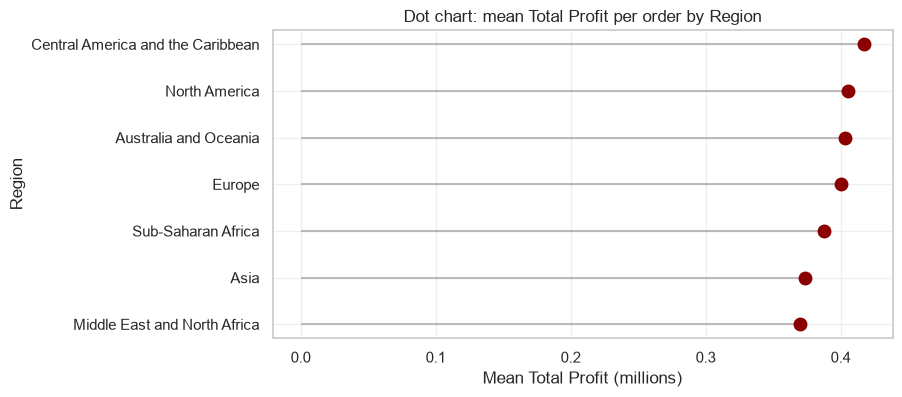

In [50]:
# Module 4: Dot chart of mean profit per order by Region
mean_profit = df_clean.groupby('Region')['Total Profit'].mean().sort_values() / 1e6
plt.figure(figsize=(8, 4))
plt.hlines(y=mean_profit.index, xmin=0, xmax=mean_profit.values, color='gray', alpha=0.5)
plt.plot(mean_profit.values, mean_profit.index, 'o', color='darkred', markersize=9)
plt.title('Dot chart: mean Total Profit per order by Region')
plt.xlabel('Mean Total Profit (millions)')
plt.ylabel('Region')
plt.show()


### Interpretation: 
Mean profit per order is similar across regions, between about 0.37 and 0.42 million.
These differences are small and no confidence intervals were computed, so they are not conclusive.

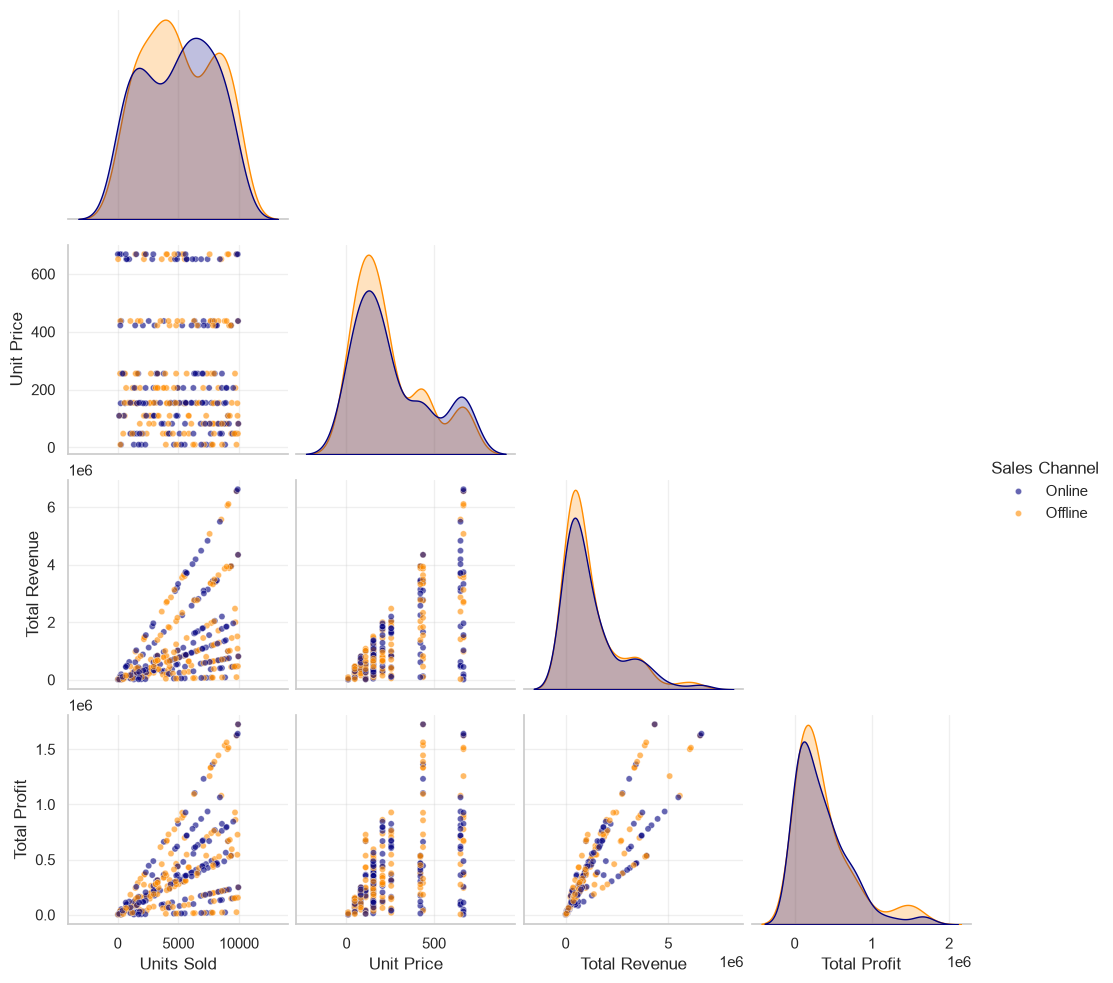

Units Sold  Total Profit
Region                            Sales Channel                          
Asia                              Offline            5014.0      438887.0
                                  Online             4949.0      306212.0
Australia and Oceania             Offline            5227.0      374228.0
                                  Online             5363.0      446554.0
Central America and the Caribbean Offline            5329.0      462204.0
                                  Online             4691.0      345850.0
Europe                            Offline            5003.0      370619.0
                                  Online             4624.0      429837.0

In [51]:
# Module 4: n-dimensional analysis with a pair plot and grouped summary table
pair_columns = ['Units Sold', 'Unit Price', 'Total Revenue', 'Total Profit']
sns.pairplot(df_clean.sample(300, random_state=RANDOM_STATE), vars=pair_columns, hue='Sales Channel',
palette=['navy', 'darkorange'], corner=True, plot_kws={'alpha': 0.6, 's': 20})
plt.show()
df_clean.groupby(['Region', 'Sales Channel'])[['Units Sold', 'Total Profit']].mean().round(0).head(8)

### Interpretation: 

The pair plot shows Total Revenue and Total Profit rising together, Units Sold and Unit
Price independent of each other, and the two sales channels overlapping in every panel. The grouped table
shows that the online-offline difference in mean profit has no consistent direction across regions.


In [53]:
# Module 4: Detect outliers in Total Profit using the IQR rule and Z-scores
profit = df_clean['Total Profit']
q1, q3 = profit.quantile(0.25), profit.quantile(0.75)
iqr = q3 - q1
iqr_outliers = df_clean[(profit < q1 - 1.5 * iqr) | (profit > q3 + 1.5 * iqr)]
z_scores = stats.zscore(profit)
z_outliers = df_clean[np.abs(z_scores) > 3]
print('IQR rule bounds: %.0f to %.0f' % (q1 - 1.5 * iqr, q3 + 1.5 * iqr))
print('Outliers by IQR rule:', len(iqr_outliers))
print('Outliers by |Z| > 3 :', len(z_outliers))


IQR rule bounds: -576745 to 1223578
Outliers by IQR rule: 55
Outliers by |Z| > 3 : 18


### Interpretation: 
The IQR rule flags 55 orders and the Z-score rule flags 18 orders. The IQR lower bound
is negative, so all flagged orders are unusually high profits. They are plausible large orders and should be
investigated, not deleted automatically.


# Module 5: Clustering Algorithms


Clustering is an unsupervised learning task that groups similar observations without using labels. Good
clusters have high similarity inside a group and low similarity between groups.

Features used: Units Sold, Unit Price, Unit Cost and Total Profit. They are standardized because distancebased methods are sensitive to scale. Categorical columns are not used here, to keep distances meaningful.
To control computation, a reproducible random sample of 500 records (seed 42) is used for the O(n²)
methods (spectral, MST, hierarchical).

Limitation: Unit Price and Unit Cost take one value per item type, so clusters are expected to follow item
type to a large extent.


In [54]:
 # Module 5: Select clustering features, standardize them and draw a reproducible sample
from sklearn.preprocessing import StandardScaler
cluster_features = ['Units Sold', 'Unit Price', 'Unit Cost', 'Total Profit']
X_all = StandardScaler().fit_transform(df_clean[cluster_features])
sample_index = df_clean.sample(500, random_state=RANDOM_STATE).index
X = StandardScaler().fit_transform(df_clean.loc[sample_index, cluster_features])
sample_df = df_clean.loc[sample_index].reset_index(drop=True)
print('Full data shape:', X_all.shape, ' Sample shape:', X.shape)


Full data shape: (1000, 4)  Sample shape: (500, 4)


## 5.1 Spectral clustering

Idea: build a similarity graph of the points, then cluster using the eigenvectors of the graph Laplacian.

### Steps:
1. Build an affinity matrix 𝑊 (here: k-nearest-neighbour graph).
2. Compute the Laplacian 𝐿 = 𝐷 − 𝑊, where 𝐷 is the degree matrix.
3. Take the 𝑘 smallest eigenvectors of 𝐿 (normalized form) as a new representation.
4. Run k-means on those eigenvectors.

It can find non-convex clusters, but the number of clusters must be chosen and it is expensive for large 𝑛.


Cluster sizes: [351  76  73]
Silhouette score: 0.400


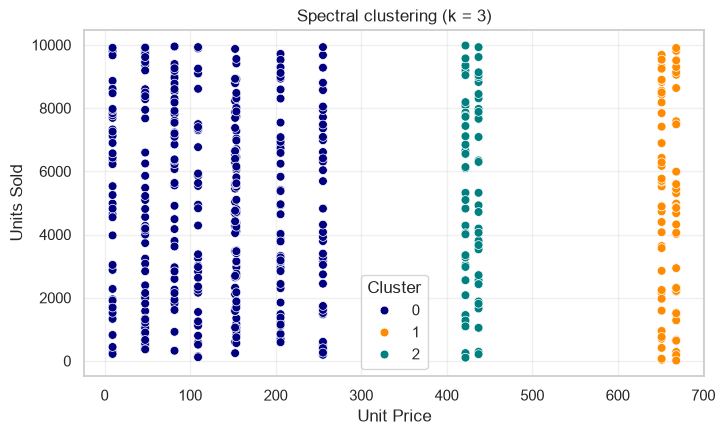

In [56]:
# Module 5: Apply spectral clustering with a nearest-neighbour affinity graph
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
spectral = SpectralClustering(n_clusters=3, affinity='nearest_neighbors', n_neighbors=10, random_state=RANDOM_STATE)
spectral_labels = spectral.fit_predict(X)
print('Cluster sizes:', np.bincount(spectral_labels))
print('Silhouette score: %.3f' % silhouette_score(X, spectral_labels))
sns.scatterplot(x=sample_df['Unit Price'], y=sample_df['Units Sold'], hue=spectral_labels,
palette=['navy', 'darkorange', 'teal'], s=40)
plt.title('Spectral clustering (k = 3)')
plt.xlabel('Unit Price')
plt.ylabel('Units Sold')
plt.legend(title='Cluster')
plt.show()


### Interpretation: 
The three clusters have 351, 76 and 73 records, but the silhouette score is only 0.4,
indicating weak separation. The data have a discrete structure (fixed prices per item type) combined with
a continuous Units Sold variable and no clear natural gaps, so clusters here are partly arbitrary.


## 5.2 Document clustering (synthetic text demonstration)
Document clustering groups text documents. Text is converted to numbers with TF-IDF:

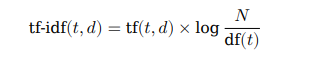

so words frequent in a document but rare across the collection get high weights.
The sales dataset has no text column, so a small synthetic collection of 9 sentences is created here
only for demonstration. It is not part of the sales data and its results are not findings about sales.


In [58]:
# Module 5: Cluster a small synthetic document collection using TF-IDF and k-means
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
documents = [
'the football team won the match with a late goal',
'the player scored in the cricket match yesterday',
'the coach praised the team after the tournament',
'the bank raised interest rates to control inflation',
'stock markets fell as investors worried about inflation',
'the company reported higher profit and revenue this quarter',
'the new phone has a faster processor and better camera',
'software update improves the battery of the laptop',
'the startup released an app using machine learning']
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(documents)
doc_labels = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(tfidf_matrix)
pd.DataFrame({'Cluster': doc_labels, 'Document': documents}).sort_values('Cluster')


,Cluster,Document
3,0,the bank raised interest rates to control infl...
4,0,stock markets fell as investors worried about ...
5,1,the company reported higher profit and revenue...
6,1,the new phone has a faster processor and bette...
7,1,software update improves the battery of the la...
8,1,the startup released an app using machine lear...
0,2,the football team won the match with a late goal
2,2,the coach praised the team after the tournament
1,2,the player scored in the cricket match yesterday


### Interpretation : 
TF-IDF with k-means separates the sports sentences (cluster 2)
and the finance/inflation sentences (cluster 0) cleanly, while the company-profit sentence falls with the
technology sentences (cluster 1). This shows the method works, and also that tiny collections can give
imperfect topic groups. These results say nothing about the sales data.


## 5.3 Minimum Spanning Tree (MST) clustering

Idea: a minimum spanning tree connects all points with the smallest total edge length. Long edges in the tree link groups that are far apart.

### Cluster-forming strategy used:
1. Compute the pairwise Euclidean distance matrix.
2. Build the MST (Kruskal/Prim via SciPy).
3. Remove the 𝑘 − 1 longest edges (here 𝑘 = 4).
4. Each connected component that remains is a cluster.
MST clustering can detect irregular shapes but is sensitive to outliers, which may form their own tiny clusters.


Edges in MST: 499  Longest edges cut: [0.6  1.05 1.41]
Cluster sizes: [351  39  34  76]


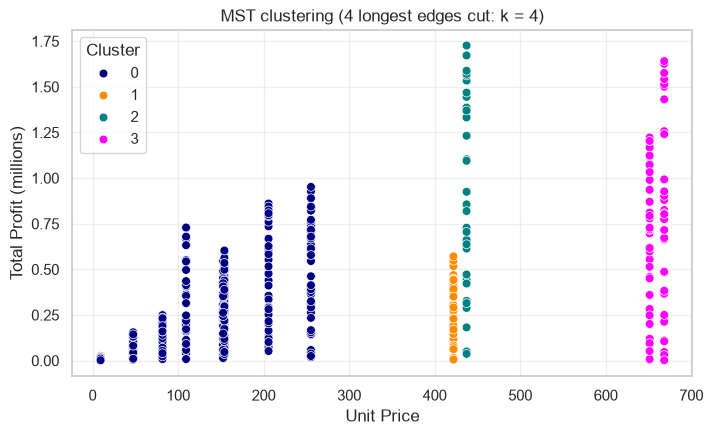

In [59]:
# Module 5: Form clusters by cutting the longest edges of a minimum spanning tree
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
distance_matrix = squareform(pdist(X, metric='euclidean'))
mst = minimum_spanning_tree(distance_matrix).toarray()
k_mst = 4
edge_rows, edge_cols = np.nonzero(mst)
edge_lengths = mst[edge_rows, edge_cols]
longest = np.argsort(edge_lengths)[-(k_mst - 1):]
mst[edge_rows[longest], edge_cols[longest]] = 0
n_components, mst_labels = connected_components(mst, directed=False)
print('Edges in MST:', len(edge_lengths), ' Longest edges cut:', np.round(edge_lengths[longest], 2))
print('Cluster sizes:', np.bincount(mst_labels))
sns.scatterplot(x=sample_df['Unit Price'], y=sample_df['Total Profit'] / 1e6, hue=mst_labels,
palette=['navy', 'darkorange', 'teal', 'magenta'], s=40)
plt.title('MST clustering (4 longest edges cut: k = 4)')
plt.xlabel('Unit Price')
plt.ylabel('Total Profit (millions)')
plt.legend(title='Cluster')
plt.show()


### Interpretation:
Cutting the three longest MST edges (lengths 0.60, 1.05 and 1.41) gives clusters of 351,
39, 34 and 76 records, with no single-point clusters. The result is one large cluster and three smaller ones,
showing that MST clustering splits only at the largest gaps and depends on the choice of k.


### 5.4 Model-based clustering and the Expectation-Maximization (EM) algorithm :

Model-based clustering assumes the data come from a mixture of probability distributions. A Gaussian
Mixture Model (GMM) is

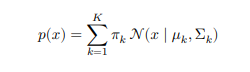

with mixing weights 𝜋𝑘
. The parameters are estimated by maximum likelihood using the EM algorithm,
which repeats:

• E-step: compute the probability (responsibility) that each point belongs to each component, using
the current parameters.

• M-step: update 𝜋𝑘
, 𝜇𝑘
, Σ𝑘 using these responsibilities.

until the log-likelihood stops improving. Thus GMM is the model and EM is the fitting algorithm. The
number of components is chosen with the Bayesian Information Criterion (BIC), where lower is better.

Best number of components by BIC: 8
EM converged: True  iterations: 34
Mixing weights: [0.078 0.129 0.258 0.089 0.075 0.077 0.082 0.212]


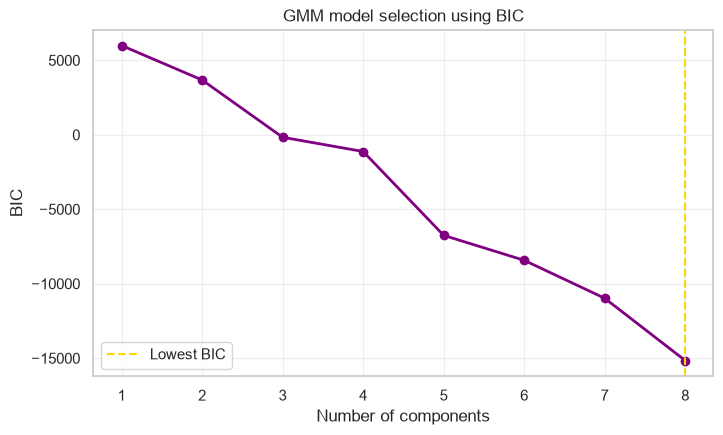

In [62]:
 # Module 5: Fit Gaussian mixture models with EM and select components by BIC
from sklearn.mixture import GaussianMixture
bic_scores = []
for n_components_gmm in range(1, 9):
    gmm_trial = GaussianMixture(n_components=n_components_gmm, random_state=RANDOM_STATE, n_init=3).fit(X_all)
    bic_scores.append(gmm_trial.bic(X_all))
best_k = int(np.argmin(bic_scores)) + 1
gmm = GaussianMixture(n_components=best_k, random_state=RANDOM_STATE, n_init=3).fit(X_all)
gmm_labels = gmm.predict(X_all)
print('Best number of components by BIC:', best_k)
print('EM converged:', gmm.converged_, ' iterations:', gmm.n_iter_)
print('Mixing weights:', np.round(gmm.weights_, 3))
plt.plot(range(1, 9), bic_scores, marker='o', color='purple', linewidth=2)
plt.axvline(best_k, color='gold', linestyle='--', label='Lowest BIC')
plt.title('GMM model selection using BIC')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.legend()
plt.show()


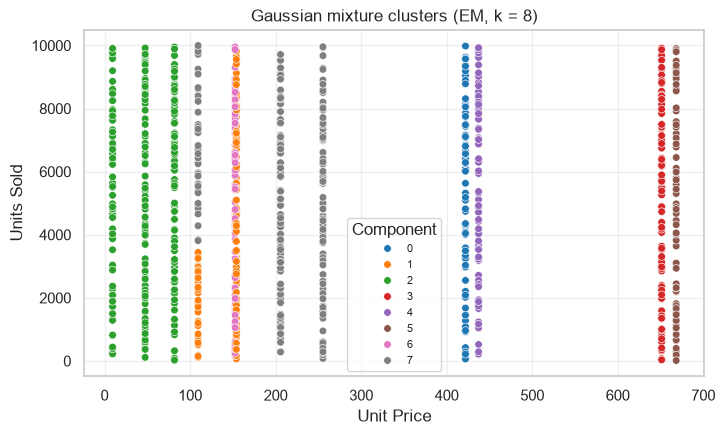

In [63]:
# Module 5: Visualize the Gaussian mixture clusters on the full data
palette_gmm = sns.color_palette('tab10', best_k)
sns.scatterplot(x=df_clean['Unit Price'], y=df_clean['Units Sold'], hue=gmm_labels,
palette=palette_gmm, s=30)
plt.title('Gaussian mixture clusters (EM, k = %d)' % best_k)
plt.xlabel('Unit Price')
plt.ylabel('Units Sold')
plt.legend(title='Component', fontsize=8)
plt.show()


### Interpretation:

The BIC decreases up to the largest number tested (8 components), so the true number
of components may be higher and BIC did not give a clear optimum within the range. EM converged in
34 iterations and the mixing weights range from about 0.075 to 0.258. The many components probably
reflect the discrete item-type structure in the data, though this was not tested directly.


## 5.5 Hierarchical agglomerative clustering

Idea: start with each point as its own cluster and repeatedly merge the two closest clusters until one remains. The merge history is shown as a dendrogram; cutting it at a height gives the clusters.
Linkage methods define the distance between clusters: single (closest pair), complete (farthest pair), average (mean of pairs) and Ward (smallest increase in within-cluster variance). The distance metric used here is Euclidean.


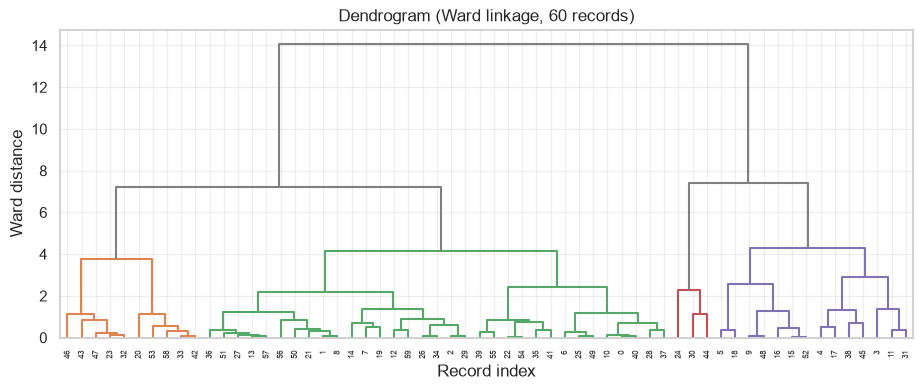

In [64]:
# Module 5: Draw a Ward-linkage dendrogram for a sample of 60 records
from scipy.cluster.hierarchy import linkage, dendrogram
linkage_matrix = linkage(X[:60], method='ward', metric='euclidean')
plt.figure(figsize=(11, 4))
dendrogram(linkage_matrix, color_threshold=7, above_threshold_color='gray')
plt.title('Dendrogram (Ward linkage, 60 records)')
plt.xlabel('Record index')
plt.ylabel('Ward distance')
plt.show()


In [66]:
# Module 5: Compare linkage methods using the silhouette score
from sklearn.cluster import AgglomerativeClustering
linkage_scores = {}
for method in ['ward', 'complete', 'average', 'single']:
    labels_method = AgglomerativeClustering(n_clusters=4, linkage=method).fit_predict(X)
    linkage_scores[method] = silhouette_score(X, labels_method)
pd.Series(linkage_scores, name='Silhouette score').round(3)

ward        0.382
complete    0.408
average     0.444
single      0.363
Name: Silhouette score, dtype: float64

Cluster sizes: [109 231 120  40]


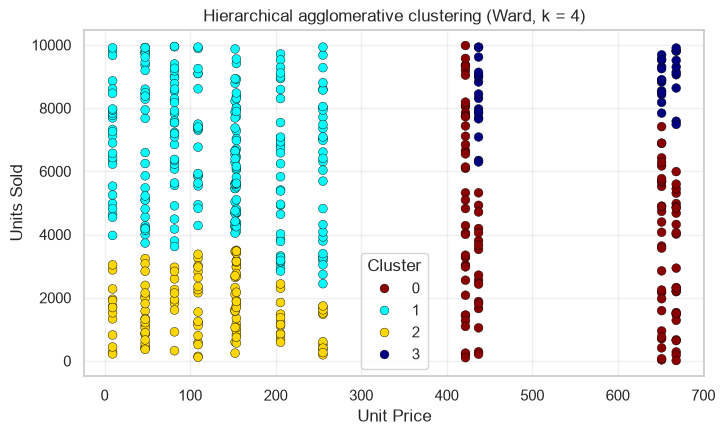

In [67]:
# Module 5: Plot the hierarchical clustering result with Ward linkage
hier_labels = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(X)
print('Cluster sizes:', np.bincount(hier_labels))
sns.scatterplot(x=sample_df['Unit Price'], y=sample_df['Units Sold'], hue=hier_labels,
palette=['darkred', 'cyan', 'gold', 'navy'], s=40, edgecolor='black', linewidth=0.3)
plt.title('Hierarchical agglomerative clustering (Ward, k = 4)')
plt.xlabel('Unit Price')
plt.ylabel('Units Sold')
plt.legend(title='Cluster')
plt.show()


### Interpretation:

With k = 4, the silhouette scores are 0.382 (Ward), 0.408 (complete), 0.444 (average)
and 0.363 (single), so average linkage scores highest. Ward was used for the plot because it usually gives
balanced groups (sizes 109, 231, 120 and 40). The cluster sizes for average linkage were not examined.
All scores are moderate, indicating reasonable but not sharp cluster structure.


### 5.6 Outlier detection using clustering

Clustering assumes normal points lie close to a cluster centre. Points far from every centre are potential
outliers. They are not automatically errors, since they may be genuine unusual sales.

(a) K-means distance method: flag points whose distance to their cluster centre is in the top 2%.

(b) DBSCAN (additional concept): Density-Based Spatial Clustering of Applications with Noise has two
parameters: 𝜀 (neighbourhood radius) and min_samples.

    • Core point: has at least min_samples points within 𝜀.
    
    • Border point: within 𝜀 of a core point but not core itself.
    
    • Noise point: neither; these are the outliers (label −1).

𝜀 is chosen from the k-distance plot at the “elbow”, and a common rule is min_samples ≥ dimensions + 1.

Distance threshold (98th percentile): 1.74
Potential outliers flagged: 20


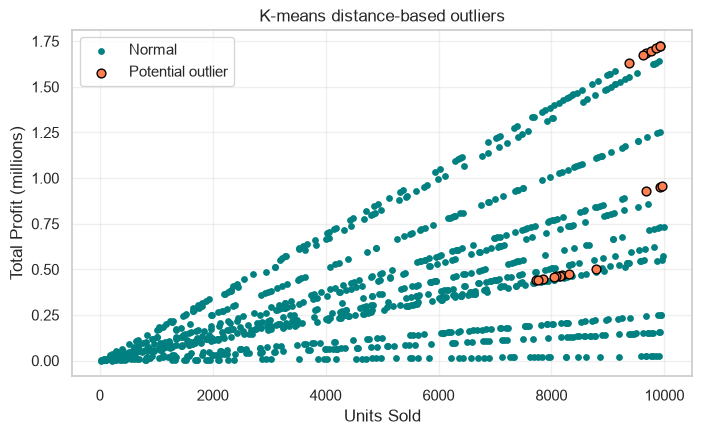

In [68]:
# Module 5: Detect outliers using distance from k-means cluster centres
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_all)
centre_distance = np.linalg.norm(X_all - kmeans.cluster_centers_[kmeans.labels_], axis=1)
threshold = np.percentile(centre_distance, 98)
kmeans_outlier = centre_distance > threshold
print('Distance threshold (98th percentile): %.2f' % threshold)
print('Potential outliers flagged:', kmeans_outlier.sum())
plt.scatter(df_clean.loc[~kmeans_outlier, 'Units Sold'], df_clean.loc[~kmeans_outlier, 'Total Profit']
/ 1e6, color='teal', s=15, label='Normal')
plt.scatter(df_clean.loc[kmeans_outlier, 'Units Sold'], df_clean.loc[kmeans_outlier, 'Total Profit']
/ 1e6, color='coral', s=40, edgecolor='black', label='Potential outlier')
plt.title('K-means distance-based outliers')
plt.xlabel('Units Sold')
plt.ylabel('Total Profit (millions)')
plt.legend()
plt.show()

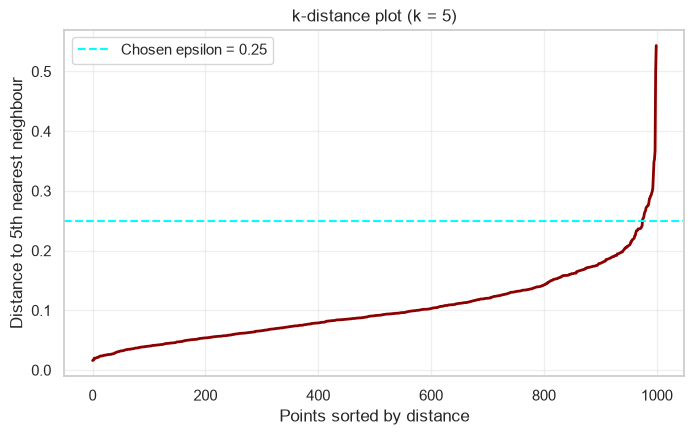

In [69]:
 # Module 5: Choose epsilon with a k-distance plot for DBSCAN
from sklearn.neighbors import NearestNeighbors
min_samples_value = 5
neighbours = NearestNeighbors(n_neighbors=min_samples_value).fit(X_all)
distances, _ = neighbours.kneighbors(X_all)
k_distance = np.sort(distances[:, -1])
plt.plot(k_distance, color='darkred', linewidth=2)
plt.axhline(0.25, color='cyan', linestyle='--', label='Chosen epsilon = 0.25')
plt.title('k-distance plot (k = 5)')
plt.xlabel('Points sorted by distance')
plt.ylabel('Distance to 5th nearest neighbour')
plt.legend()
plt.show()


Clusters found: 13
Core points : 975
Border points: 17
Noise points : 8


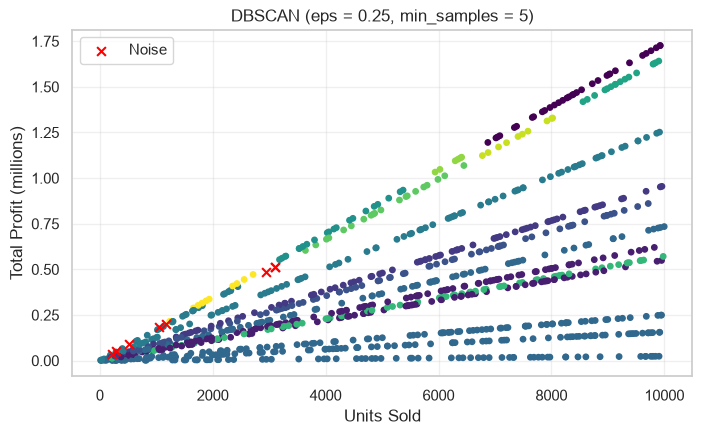

In [70]:
# Module 5: Apply DBSCAN and identify core, border and noise points
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.25, min_samples=min_samples_value).fit(X_all)
db_labels = dbscan.labels_
core_mask = np.zeros(len(db_labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
noise_mask = db_labels == -1
border_mask = ~core_mask & ~noise_mask
print('Clusters found:', len(set(db_labels)) - (1 if -1 in db_labels else 0))
print('Core points :', core_mask.sum())
print('Border points:', border_mask.sum())
print('Noise points :', noise_mask.sum())
plt.scatter(df_clean.loc[~noise_mask, 'Units Sold'], df_clean.loc[~noise_mask, 'Total Profit'] / 1e6,
c=db_labels[~noise_mask], cmap='viridis', s=15)
plt.scatter(df_clean.loc[noise_mask, 'Units Sold'], df_clean.loc[noise_mask, 'Total Profit'] / 1e6,
color='red', marker='x', s=40, label='Noise')
plt.title('DBSCAN (eps = 0.25, min_samples = 5)')
plt.xlabel('Units Sold')
plt.ylabel('Total Profit (millions)')
plt.legend()
plt.show()


### Interpretation: 

The k-means method flags 20 records (2%) by design of the percentile threshold. DBSCAN with ε = 0.25 and min_samples = 5 finds 13 dense clusters with 975 core points, 17 border points
and 8 noise points. The two methods define outliers differently (distance from a centre versus low local density), and the overlap between them was not checked. The flagged records are potential anomalies
only. They may be legitimate unusual orders and need domain review. DBSCAN is sensitive to ε: an initial
value of 0.5 labelled no points as noise.


# Module 6: Dimensionality Reduction


### Dimensionality reduction :

It represents data with fewer variables while keeping as much structure as
possible. It reduces noise and computation and helps visualization and the “curse of dimensionality” in high-dimensional data.

    • Feature selection keeps a subset of the original variables.
    
    • Feature extraction creates new variables from combinations of the originals (PCA, SVD, etc.).
    
Input features: the six numerical columns (Units Sold, Unit Price, Unit Cost, Total Revenue, Total Cost, Total Profit), standardized. Because the columns are strongly correlated, the data should compress well.
For the slower methods (MDS, Isomap, SOM), a reproducible sample of 500 records is used.

In [71]:
# Module 6: Standardize the six numerical features for dimensionality reduction
dr_features = ['Units Sold', 'Unit Price', 'Unit Cost', 'Total Revenue', 'Total Cost', 'Total Profit']
X_dr = StandardScaler().fit_transform(df_clean[dr_features])
X_dr_sample = X_dr[df_clean.index.get_indexer(sample_index)]
item_sample = df_clean.loc[sample_index, 'Item Type'].values
print('Full:', X_dr.shape, ' Sample:', X_dr_sample.shape)


Full: (1000, 6)  Sample: (500, 6)


### 6.1 Principal Component Analysis (PCA)

PCA finds orthogonal directions (principal components) of maximum variance. Components are eigenvectors of the covariance matrix 𝐶, with eigenvalues 𝜆𝑖 giving the variance explained:

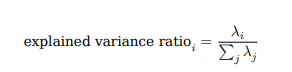

It is linear, sensitive to scaling, and components can be hard to interpret.


     Explained  Cumulative
PC1     0.7076      0.7076
PC2     0.2255      0.9331
PC3     0.0396      0.9727
PC4     0.0268      0.9995
PC5     0.0005      1.0000
PC6     0.0000      1.0000


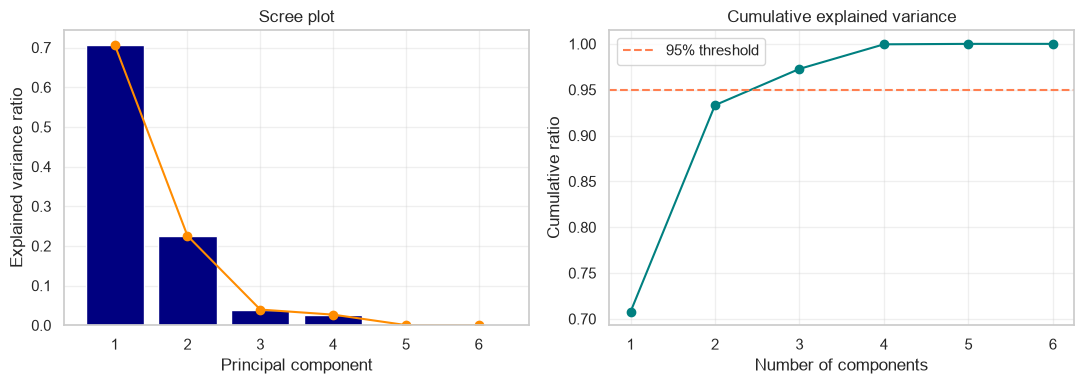

In [72]:
# Module 6: Apply PCA and plot the scree plot with explained variance
from sklearn.decomposition import PCA
pca = PCA(random_state=RANDOM_STATE).fit(X_dr)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
print(pd.DataFrame({'Explained': explained, 'Cumulative': cumulative}, index=['PC%d' % i for i in
range(1, 7)]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(range(1, 7), explained, color='navy')
axes[0].plot(range(1, 7), explained, color='darkorange', marker='o')
axes[0].set_title('Scree plot')
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance ratio')
axes[1].plot(range(1, 7), cumulative, color='teal', marker='o')
axes[1].axhline(0.95, color='coral', linestyle='--', label='95% threshold')
axes[1].set_title('Cumulative explained variance')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative ratio')
axes[1].legend()
plt.tight_layout()
plt.show()


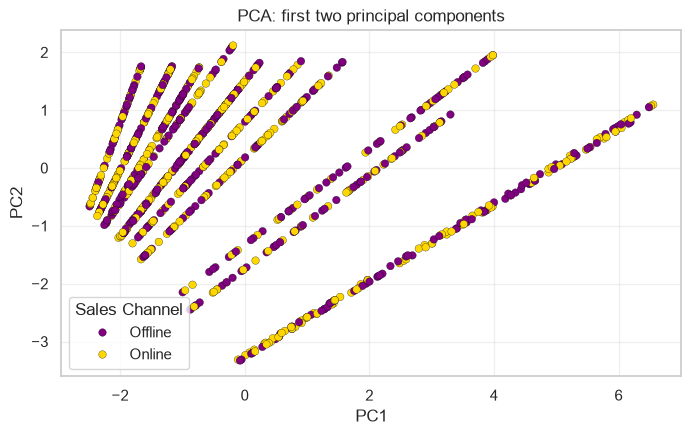

     Units Sold  Unit Price  Unit Cost  Total Revenue  Total Cost  \
PC1        0.22        0.41       0.40           0.47        0.47   
PC2        0.72       -0.43      -0.45           0.12        0.06   

     Total Profit  
PC1          0.42  
PC2          0.28  


In [73]:
# Module 6: Project the data onto the first two principal components
pca_scores = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_dr)
sns.scatterplot(x=pca_scores[:, 0], y=pca_scores[:, 1], hue=df_clean['Sales Channel'],
palette=['purple', 'gold'], s=30, edgecolor='black', linewidth=0.2)
plt.title('PCA: first two principal components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()
print(pd.DataFrame(pca.components_[:2], columns=dr_features, index=['PC1', 'PC2']).round(2))

### Interpretation:

PC1 explains 70.8% of the variance and PC2 22.6%, a cumulative 93.3%; three components reach 97.3%. PC1 has positive weights on all variables (largest on Total Revenue and Total Cost,
about 0.47), so it acts as an overall size/monetary-scale component. PC2 contrasts Units Sold (+0.72) with
Unit Price and Unit Cost (about −0.43 and −0.45). The 2-D projection shows points in parallel diagonal
streaks, which is consistent with the fixed unit price and cost of each item type; the two sales channels
overlap completely

### 6.2 Singular Value Decomposition (SVD)

SVD factorizes any matrix 𝑋 (𝑛 × 𝑝) as

𝑋 = 𝑈 Σ 𝑉^𝑇

where 𝑈 and 𝑉 have orthonormal columns and Σ is diagonal with singular values 𝜎1 ≥ 𝜎2 ≥ … ≥ 0. For
centred data, the variance along component 𝑖 is 𝜎^
2
/(𝑛−1), so PCA can be computed through SVD. Keeping
only the largest singular values gives the best low-rank approximation of 𝑋.

In [74]:
 # Module 6: Compute SVD with NumPy and compare it with PCA
U, singular_values, Vt = np.linalg.svd(X_dr, full_matrices=False)
variance_from_svd = singular_values ** 2 / (len(X_dr) - 1)
print('Singular values:', np.round(singular_values, 2))
print('Variance ratio from SVD:', np.round(variance_from_svd / variance_from_svd.sum(), 4))
print('Variance ratio from PCA:', np.round(explained, 4))
X_rank2 = U[:, :2] @ np.diag(singular_values[:2]) @ Vt[:2, :]
print('Relative reconstruction error with 2 singular values: %.4f' % (np.linalg.norm(X_dr - X_rank2)
/ np.linalg.norm(X_dr)))


Singular values: [65.16 36.78 15.41 12.68  1.71  0.  ]
Variance ratio from SVD: [7.076e-01 2.255e-01 3.960e-02 2.680e-02 5.000e-04 0.000e+00]
Variance ratio from PCA: [7.076e-01 2.255e-01 3.960e-02 2.680e-02 5.000e-04 0.000e+00]
Relative reconstruction error with 2 singular values: 0.2586


### Interpretation:

The variance ratios from SVD are identical to those from PCA, confirming that PCA on
standardized data is obtained from the SVD. The last singular value is essentially zero because Total Profit
= Total Revenue − Total Cost, an exact linear dependence. Keeping two singular values leaves a relative
reconstruction error of about 25.9%.


### 6.3 Factor Analysis
Factor analysis assumes the observed variables are produced by a few unobserved latent factors plus
noise:

𝑥 = Λ𝑓 + 𝜀

where Λ contains the factor loadings (how strongly each variable relates to each factor). Unlike PCA, it
models shared variance and treats each variable’s unique noise separately.

               Factor 1  Factor2
Units Sold        0.459   -0.601
Unit Price        0.805    0.572
Unit Cost         0.796    0.605
Total Revenue     0.993   -0.120
Total Cost        0.988   -0.055
Total Profit      0.852   -0.297


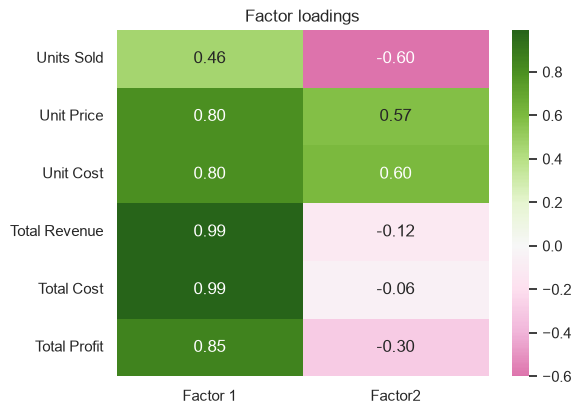

In [76]:
# Module 6: Fit a two-factor model and display the factor loadings
from sklearn.decomposition import FactorAnalysis
factor_model = FactorAnalysis(n_components=2, random_state=RANDOM_STATE).fit(X_dr)
loadings = pd.DataFrame(factor_model.components_.T, index=dr_features, columns=['Factor 1', 'Factor2'])
print(loadings.round(3))
plt.figure(figsize=(6, 4.5))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='PiYG', center=0)
plt.title('Factor loadings')
plt.show()


### Interpretation:

Factor 1 loads heavily on Total Revenue (0.99), Total Cost (0.99), Total Profit (0.85) and
the unit values (about 0.8), so it reflects overall monetary scale. Factor 2 contrasts Units Sold (−0.60) with
Unit Price and Unit Cost (about +0.57 and +0.61); the sign of a factor is arbitrary. Naming the factors is
a subjective judgement.


### 6.4 Intrinsic dimensionality
The intrinsic dimensionality is the minimum number of variables needed to describe the data without
much loss. It depends on the data and on the estimation method. Two practical estimates are used: (a)
the number of PCA components required for 95% of the variance, and (b) Minka’s maximum-likelihood
estimate (n_components='mle').

In [77]:
 # Module 6: Estimate the intrinsic dimensionality of the numerical features
components_95 = int(np.argmax(cumulative >= 0.95)) + 1
pca_mle = PCA(n_components='mle', svd_solver='full').fit(X_dr)
print('Components for 95% variance:', components_95)
print('Components chosen by MLE :', pca_mle.n_components_)


Components for 95% variance: 3
Components chosen by MLE : 5


### Interpretation: 

Three components are needed for 95% of the variance, while the MLE method selects
5. The estimates differ because they answer different questions: 95% variance is a threshold choice, and
MLE detects the exact dependence that leaves five independent directions. This confirms that intrinsic
dimensionality depends on the method.

## 6.5 Multidimensional Scaling (MDS)
MDS places points in a low-dimensional space so that the pairwise distances are preserved as well as
possible, by minimizing the stress:

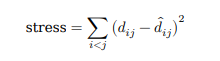

where 𝑑𝑖𝑗 are original and 𝑑 ̂
𝑖𝑗 embedded distances. It is computationally expensive (O(n²)), hence the
500-record sample.

# Module 6: Compute a two-dimensional MDS embedding of the sample
from sklearn.manifold import MDS
mds = MDS(n_components=2, random_state=RANDOM_STATE, n_init=1, max_iter=300)
mds_embedding = mds.fit_transform(X_dr_sample)
print('Final stress: %.2f' % mds.stress_)
sns.scatterplot(x=mds_embedding[:, 0], y=mds_embedding[:, 1], hue=item_sample, palette='tab20', s=35)
plt.title('MDS embedding (coloured by Item Type)')
plt.xlabel('MDS dimension 1')
plt.ylabel('MDS dimension 2')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()


### Interpretation:

The MDS embedding of the 500-record sample has a final stress of about 2293.6. Raw
stress depends on the scale of the data, so it is useful mainly for comparing embeddings. In the plot, points
coloured by Item Type show whether similar item types are placed near each other in two dimensions. The
points form several straight streaks, consistent with the fixed price and cost per item type, rather than
separate blobs.

### 6.6 Manifold learning (Isomap)
Manifold learning assumes the data lie on a low-dimensional curved surface inside a high-dimensional
space. Isomap builds a nearest-neighbour graph, computes geodesic (shortest-path) distances along it,
and then applies MDS to those distances. It can unfold curved structure that PCA cannot, but it is sensitive
to the neighbourhood size.


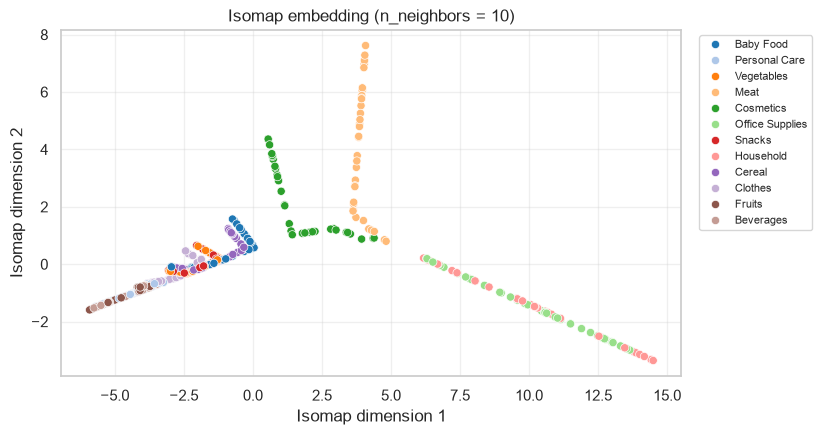

In [80]:
# Module 6: Apply Isomap to learn a two-dimensional manifold embedding
from sklearn.manifold import Isomap
isomap_embedding = Isomap(n_neighbors=10, n_components=2).fit_transform(X_dr_sample)
sns.scatterplot(x=isomap_embedding[:, 0], y=isomap_embedding[:, 1], hue=item_sample, palette='tab20',
s=35)
plt.title('Isomap embedding (n_neighbors = 10)')
plt.xlabel('Isomap dimension 1')
plt.ylabel('Isomap dimension 2')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()


### Interpretation:

Isomap uses geodesic distances along a 10-neighbour graph. Comparing it with the MDS
plot shows how much the neighbourhood-based method changes the layout of the same points. Because
the six features are largely linear combinations of each other, a strongly curved manifold is not expected,
and the linear methods already capture most of the structure.


## 6.7 Self-Organizing Maps (SOM)

A Self-Organizing Map is a neural network that maps data onto a 2-D grid of neurons. For each input,
the best-matching neuron (winner) and its neighbours on the grid are moved towards the input, with
the neighbourhood and learning rate shrinking over time. As a result, similar records end up on nearby
neurons, preserving topology. The U-matrix (distance map) shows the average distance between neighbouring neurons, where bright areas indicate cluster borders.


In [81]:
# Module 6: Install the MiniSom library required for the self-organizing map
!pip install -q minisom



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Quantization error: 0.390


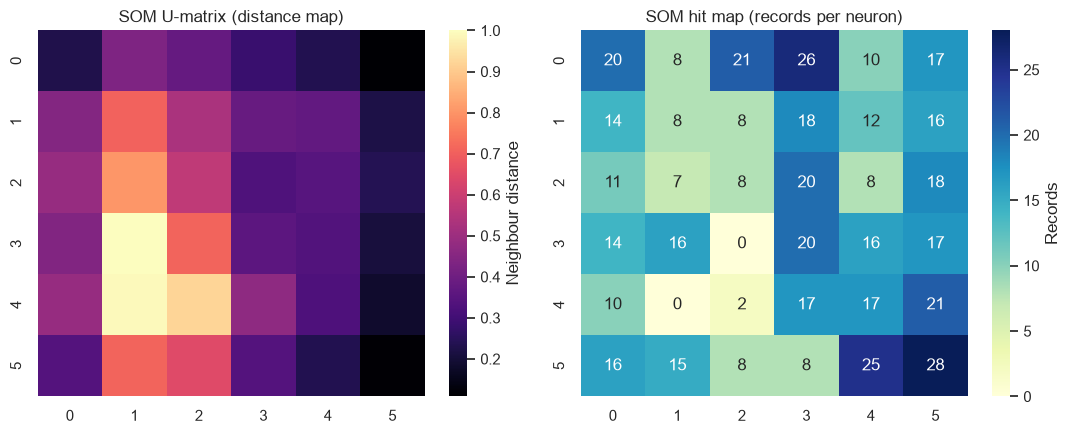

In [83]:
# Module 6: Train a self-organizing map and plot its distance map and hit map
from minisom import MiniSom
som = MiniSom(x=6, y=6, input_len=X_dr_sample.shape[1], sigma=1.5, learning_rate=0.5, random_seed=RANDOM_STATE)
som.train_random(X_dr_sample, num_iteration=2000)
hits = np.zeros((6, 6))
for record in X_dr_sample:
    winner = som.winner(record)
    hits[winner] += 1
print('Quantization error: %.3f' % som.quantization_error(X_dr_sample))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(som.distance_map().T, cmap='magma', ax=axes[0], cbar_kws={'label': 'Neighbour distance'})
axes[0].set_title('SOM U-matrix (distance map)')
sns.heatmap(hits.T, cmap='YlGnBu', annot=True, fmt='.0f', ax=axes[1], cbar_kws={'label': 'Records'})
axes[1].set_title('SOM hit map (records per neuron)')
plt.tight_layout()
plt.show()


### Interpretation:
The 6 × 6 SOM has a quantization error of 0.390 (average distance from a record to its
winning neuron in standardized units). The U-matrix highlights borders between neuron groups, and the
hit map shows how the 500 records are spread over the 36 neurons. Map size and training length were
fixed choices and were not tuned.


# Module 7: Model Development and Evaluation

Linear regression models a numeric target as a linear combination of features:
    
̂𝑦 = 𝛽0 + 𝛽1𝑥1 + ⋯ + 𝛽𝑝𝑥𝑝

with coefficients chosen to minimize the sum of squared errors.
    
### Modelling choices

    • Target: Total Profit (continuous numeric).
    • Features: Units Sold, Unit Price, Unit Cost, plus one-hot encoded Region, Item Type and Sales
    Channel.
    • Excluded to avoid target leakage: Total Revenue and Total Cost, because Total Profit = Total
    Revenue − Total Cost, so including them would give the answer away.
    • No data leakage: the data are split first (80/20, seed 42), and scaling and encoding are fitted on
    the training set only, using a pipeline.


In [85]:
# Module 7: Select features and target and split into training and test sets
from sklearn.model_selection import train_test_split
numeric_features = ['Units Sold', 'Unit Price', 'Unit Cost']
categorical_features = ['Region', 'Item Type', 'Sales Channel']
target = 'Total Profit'
missing_columns = [c for c in numeric_features + categorical_features + [target] if c not in df_clean.columns]
assert len(missing_columns) == 0, missing_columns
X_reg = df_clean[numeric_features + categorical_features]
y_reg = df_clean[target]
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)
print('Training rows:', len(X_train), ' Test rows:', len(X_test))


Training rows: 800  Test rows: 200


In [87]:
# Module 7: Build a preprocessing and linear regression pipeline and fit it on training data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
preprocessor = ColumnTransformer([('numeric', StandardScaler(), numeric_features),('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)])
model = Pipeline([('preprocess', preprocessor), ('regression', LinearRegression())])
model.fit(X_train, y_train)
print('Model fitted. Number of input columns after encoding:', model.named_steps['regression'].coef_.shape[0])


Model fitted. Number of input columns after encoding: 24


Regression metrics

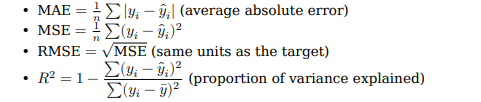

Accuracy (the proportion of correct predictions) is a classification metric. A regression model predicts
continuous values that are almost never exactly equal to the true value, so error metrics and 𝑅2 are used
instead.

In [89]:
# Module 7: Evaluate the regression model on training and test sets
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return [mean_absolute_error(actual, predicted), mse, np.sqrt(mse), r2_score(actual, predicted)]
metrics_table = pd.DataFrame({'Train': regression_metrics(y_train, y_train_pred), 'Test': regression_metrics(y_test, y_test_pred)}, index=['MAE', 'MSE', 'RMSE', 'R2'])
print('Mean of Total Profit in test set: %.0f' % y_test.mean())
metrics_table.round(3)


Mean of Total Profit in test set: 345416


,Train,Test
MAE,1.081258e+05,1.115019e+05
MSE,2.271483e+10,2.627091e+10
RMSE,1.507144e+05,1.620830e+05
R2,8.490000e-01,7.960000e-01


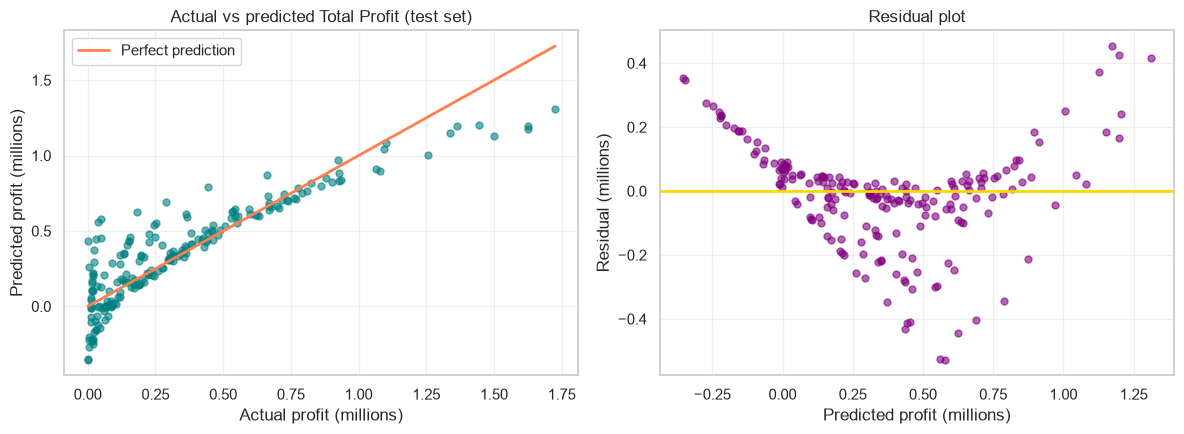

In [90]:
 # Module 7: Plot actual versus predicted profit and the residuals
residuals = y_test - y_test_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test / 1e6, y_test_pred / 1e6, color='teal', alpha=0.6, s=25)
axes[0].plot([0, y_test.max() / 1e6], [0, y_test.max() / 1e6], color='coral', linewidth=2, label='Perfect prediction')
axes[0].set_title('Actual vs predicted Total Profit (test set)')
axes[0].set_xlabel('Actual profit (millions)')
axes[0].set_ylabel('Predicted profit (millions)')
axes[0].legend()
axes[1].scatter(y_test_pred / 1e6, residuals / 1e6, color='purple', alpha=0.6, s=25)
axes[1].axhline(0, color='gold', linewidth=2)
axes[1].set_title('Residual plot')
axes[1].set_xlabel('Predicted profit (millions)')
axes[1].set_ylabel('Residual (millions)')
plt.tight_layout()
plt.show()


### Interpretation:

On the test set, MAE = 111,502, RMSE = 162,083 and R² = 0.796, compared with a
train R² of 0.849. The small train–test gap suggests no serious overfitting. The RMSE is about 47% of
the mean test profit (345,416), so individual predictions are still fairly imprecise. A likely reason is that
profit equals Units Sold × (Unit Price − Unit Cost), a multiplicative relationship that a purely linear model
cannot represent exactly.


### Confusion Matrix

A confusion matrix is a table used to evaluate the performance of a classification model by comparing actual class labels with predicted class labels. It shows the number of correct and incorrect predictions for each class.

For binary classification, the confusion matrix contains four values:

- **True Positive (TP):** The model correctly predicts the positive class.
- **True Negative (TN):** The model correctly predicts the negative class.
- **False Positive (FP):** The model incorrectly predicts the positive class.
- **False Negative (FN):** The model incorrectly predicts the negative class.

For a binary classification problem, the matrix is conventionally represented as:

|  | Predicted Negative | Predicted Positive |
|---|---:|---:|
| Actual Negative | TN | FP |
| Actual Positive | FN | TP |

The confusion matrix helps calculate classification metrics such as accuracy, precision, recall, and F1-score.

**Accuracy formula:**

Accuracy = (TP + TN) / (TP + TN + FP + FN)

In this demonstration, synthetic class labels are used because the main sales model predicts continuous profit values. A confusion matrix is not directly suitable for evaluating that regression model.

Confusion Matrix:
                     Predicted Negative (0)  Predicted Positive (1)
Actual Negative (0)                       4                       1
Actual Positive (1)                       1                       4

Accuracy: 0.8
Precision: 0.8
Recall: 0.8
F1-score: 0.8


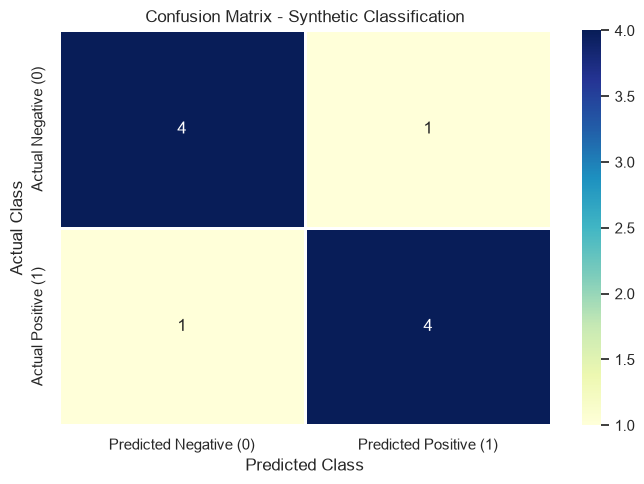

In [92]:

# Module 7: Calculate and visualize the confusion matrix for synthetic classification labels
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

true_labels = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
predicted_labels = [1, 0, 1, 0, 0, 1, 1, 0, 1, 0]

cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1])

cm_table = pd.DataFrame(
    cm,
    index=["Actual Negative (0)", "Actual Positive (1)"],
    columns=["Predicted Negative (0)", "Predicted Positive (1)"]
)

print("Confusion Matrix:")
print(cm_table)

print("\nAccuracy:", round(accuracy_score(true_labels, predicted_labels), 3))
print("Precision:", round(precision_score(true_labels, predicted_labels), 3))
print("Recall:", round(recall_score(true_labels, predicted_labels), 3))
print("F1-score:", round(f1_score(true_labels, predicted_labels), 3))

plt.figure(figsize=(7, 5))
sns.heatmap(cm_table, annot=True, fmt="d", cmap="YlGnBu", linewidths=1, linecolor="white")
plt.title("Confusion Matrix - Synthetic Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


### Interpretation

The confusion matrix contains 10 observations, of which 8 are classified correctly and 2 are misclassified. The model correctly predicts 4 negative cases and 4 positive cases, while producing 1 false positive and 1 false negative.

The accuracy, precision, recall, and F1-score are all 0.80 (80%) for this balanced synthetic example. This indicates that the predictions are correct for 80% of the observations. However, these results are only illustrative because the class labels are manually specified and do not come from a trained model or the original sales dataset.

The confusion matrix demonstrates how classification performance can be evaluated. It should not be used to assess the linear regression model in this assignment, which predicts continuous Total Profit values and is evaluated using MAE, MSE, RMSE, and R².

### Accuracy demonstration (classification, synthetic). 

The small example below uses hand-written true
and predicted class labels. It is not related to the sales regression and only shows how classification
accuracy is computed.


In [93]:
 # Module 7: Demonstrate classification accuracy on a tiny synthetic label set
from sklearn.metrics import accuracy_score, confusion_matrix
true_labels = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
predicted_labels = [1, 0, 1, 0, 0, 1, 1, 0, 1, 0]
print('Accuracy:', accuracy_score(true_labels, predicted_labels))
print('Confusion matrix:')
print(confusion_matrix(true_labels, predicted_labels))


Accuracy: 0.8
Confusion matrix:
[[4 1]
 [1 4]]


# Reinforcement learning

## Supervised vs reinforcement learning

| Aspect   | Supervised learning       | Reinforcement learning          |
|----------|---------------------------|---------------------------------|
| Data     | Labelled examples         | Interaction with an environment |
| Feedback | Correct answer for every input | Delayed numeric reward       |
| Goal     | Predict labels or values  | Maximize cumulative reward      |
| Example  | Predicting profit         | Learning to play a game         |

**Fundamentals:** an **agent** observes the **state** of an **environment**, takes an **action**, and receives a **reward**. The agent’s strategy is its **policy**. In Q-learning the value of taking action \(a\) in state \(s\) is updated by

$$
Q(s,a) \leftarrow Q(s,a) + \alpha \left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right]
$$

**Applications:** game playing, robotics, recommendation systems, autonomous driving, dynamic pricing and inventory control, and resource allocation.

**The sales dataset is not a reinforcement learning environment** (it has no agent actions or rewards). The demonstration below is a separate, tiny, synthetic example: an agent in a corridor of 5 cells learns to walk right to reach a reward in the last cell.

In [95]:
# Module 7: Train a Q-learning agent in a small synthetic corridor environment
n_states, n_actions = 5, 2
q_table = np.zeros((n_states, n_actions))
alpha, gamma, epsilon, episodes = 0.5, 0.9, 0.2, 200
rng_rl = np.random.default_rng(RANDOM_STATE)
episode_rewards = []
for episode in range(episodes):
    state, total_reward = 0, 0
    while state != n_states - 1:
        if rng_rl.random() < epsilon:
            action = int(rng_rl.integers(n_actions))
        else:
            action = int(np.argmax(q_table[state]))
        next_state = min(state + 1, n_states - 1) if action == 1 else max(state - 1, 0)
        reward = 1 if next_state == n_states - 1 else 0
        q_table[state, action] += alpha * (reward + gamma * np.max(q_table[next_state]) - q_table[state,action])
        state, total_reward = next_state, total_reward + reward
        episode_rewards.append(total_reward)
policy = ['Left' if np.argmax(q_table[s]) == 0 else 'Right' for s in range(n_states - 1)]
print('Learned policy for states 0-3:', policy)
print(pd.DataFrame(q_table, columns=['Left', 'Right']).round(3))


Learned policy for states 0-3: ['Right', 'Right', 'Right', 'Right']
    Left  Right
0  0.656  0.729
1  0.656  0.810
2  0.729  0.900
3  0.810  1.000
4  0.000  0.000


### Interpretation:

The learned policy is ‘Right’ in every non-terminal state. The
Q-values for ‘Right’ increase towards the goal (0.729, 0.810, 0.900, 1.000), consistent with a discount
factor of 0.9. Left in state 0 has a lower value (0.656), so the agent prefers to move toward the reward.


### Results and Discussion

#### Dataset characteristics and data quality

The dataset has 1000 orders and 14 columns (5 categorical,
2 dates, 1 identifier, 6 numerical) covering 1 January 2010 to 26 July 2017. It has no missing values and
no duplicate rows. Missing-data techniques were demonstrated on an artificially modified copy (about 5%
removed from three columns), not on real gaps.
39

#### Statistical findings 

Units Sold is nearly symmetric and flat (skewness −0.05, kurtosis −1.22), while the
money variables are right-skewed, with mean Total Profit (391,203) above the median (277,226). The IQR
rule flagged 55 and the Z-score rule 18 high-profit orders.


#### Relationships. 

Units Sold and Unit Price are uncorrelated, while Total Profit has moderate correlation
with both (about 0.59 and 0.57). Unit Price and Unit Cost are almost perfectly related (r ≈ 0.99) and fixed
per item type. Region and Sales Channel are not significantly associated (p = 0.249).


#### Visual and time series patterns. 
Cosmetics, Household and Office Supplies give the most total profit.
Mean profit per order differs only slightly across regions (0.37–0.42 million). Yearly revenue was 150–195
million in 2010–2016 (2017 is incomplete). No strong trend, seasonality or autocorrelation was found in
monthly revenue.


#### Outliers. 
K-means distance (20 records) and DBSCAN (8 noise records) flag potential anomalies. These
are candidates for review, not confirmed errors.


#### Clustering

Silhouette scores are low to moderate (spectral 0.073; hierarchical 0.36–0.44 for k = 4), and
BIC did not settle on a number of GMM components within the tested range. Cluster structure is weak
and partly driven by the fixed price levels of the item types. The document-clustering result comes from
synthetic text only.


#### Dimensionality reduction. 
Two principal components explain 93.3% of the variance and three explain
97.3%. SVD reproduces PCA exactly, and the near-zero last singular value reflects Total Profit = Total
Revenue − Total Cost. Intrinsic dimensionality was estimated as 3 (95% variance) or 5 (MLE), depending
on the method.


#### Regression. 
Linear regression predicting Total Profit (without Revenue or Cost, to avoid leakage)
achieved test R² = 0.796, RMSE = 162,083 and MAE = 111,502. The reinforcement-learning and
classification-accuracy examples are synthetic demonstrations and are unrelated to the sales data.


#### Limitations. 

The data are observational and sparse over time, derived columns are built-in functions of
other columns, and price and cost are determined by item type. Sampling (500 records) was used for the
slower methods.


#### Conclusion. 
The sales data are clean and suitable for introductory EDA. Order profit is driven mainly by
quantity and the item’s price and cost, whereas region and channel show little difference.